# Homework 4

## Data Setup

I use the AReM data from Homework 3.
I keep the same training and test sets.
Each CSV file represents one activity instance.

In [1]:
from pathlib import Path
import sys

print("Python:", sys.executable)
print("Working directory:", Path.cwd())

data_dir = Path("../Homework3/data/AReM").resolve()

print("Data folder:", data_dir)
print("Data folder exists:", data_dir.is_dir())

csv_files = sorted(data_dir.glob("*/*.csv"))

print("Number of CSV files:", len(csv_files))

for folder in sorted(data_dir.iterdir()) if data_dir.is_dir() else []:
    if folder.is_dir():
        count = len(list(folder.glob("*.csv")))
        print(f"{folder.name}: {count} files")

assert data_dir.is_dir(), "The data folder was not found."
assert len(csv_files) == 88, "Expected 88 CSV files."

Python: C:\Users\19098\DSCI-552\.venv\Scripts\python.exe
Working directory: C:\Users\19098\DSCI-552\Homework4
Data folder: C:\Users\19098\DSCI-552\Homework3\data\AReM
Data folder exists: True
Number of CSV files: 88
bending1: 7 files
bending2: 6 files
cycling: 15 files
lying: 15 files
sitting: 15 files
standing: 15 files
walking: 15 files


### Load Data and Set Labels

I read all 88 CSV files and fix small format issues.
I keep the original rows in each file.

For binary classification, bending1 and bending2 have label 1.
All other activities have label 0.

I use the same training and test split as Homework 3.

In [2]:
import numpy as np
import pandas as pd

sensor_columns = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23"
]

columns = ["time"] + sensor_columns


def read_instance(path):
    rows = []

    for line_number, line in enumerate(
        path.read_text(encoding="utf-8-sig").splitlines(),
        start=1
    ):
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        line = line.rstrip(", \t")

        fields = line.split(",") if "," in line else line.split()

        if len(fields) != 7:
            raise ValueError(
                f"{path}: line {line_number} has {len(fields)} fields."
            )

        rows.append([float(value) for value in fields])

    return pd.DataFrame(rows, columns=columns)


instances = []
records = []

for path in csv_files:
    activity = path.parent.name
    dataset_id = int(path.stem.replace("dataset", ""))
    is_bending = activity in ["bending1", "bending2"]

    # Use the test files listed in the assignment.
    test_ids = {1, 2} if is_bending else {1, 2, 3}
    split = "test" if dataset_id in test_ids else "train"

    df = read_instance(path)
    instances.append(df)

    records.append({
        "activity": activity,
        "filename": path.name,
        "dataset_id": dataset_id,
        "split": split,
        "binary_label": int(is_bending),
        "rows": len(df),
        "missing_values": int(df.isna().sum().sum())
    })

metadata = pd.DataFrame(records)

train_mask = metadata["split"].eq("train")
test_mask = metadata["split"].eq("test")

y_train_binary = metadata.loc[
    train_mask, "binary_label"
].to_numpy()

y_test_binary = metadata.loc[
    test_mask, "binary_label"
].to_numpy()

print("Total instances:", len(instances))
print("Training instances:", int(train_mask.sum()))
print("Test instances:", int(test_mask.sum()))
print("Total missing values:", int(metadata["missing_values"].sum()))

print("\nInstances by activity:")
display(
    pd.crosstab(metadata["activity"], metadata["split"])
    .reindex(columns=["train", "test"])
)

print("\nBinary class counts: 0 = other, 1 = bending")
display(
    pd.crosstab(metadata["binary_label"], metadata["split"])
    .reindex(columns=["train", "test"])
)

print("\nRow counts:")
display(metadata["rows"].value_counts().sort_index())

assert len(instances) == 88
assert train_mask.sum() == 69
assert test_mask.sum() == 19
assert metadata["missing_values"].sum() == 0
assert y_train_binary.sum() == 9
assert y_test_binary.sum() == 4

Total instances: 88
Training instances: 69
Test instances: 19
Total missing values: 0

Instances by activity:


split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3



Binary class counts: 0 = other, 1 = bending


split,train,test
binary_label,,
0,60,15
1,9,4



Row counts:


rows
479     1
480    87
Name: count, dtype: int64

## 2. Time Series Classification Part 2

### (a) Binary Classification Using Logistic Regression

#### (i) Scatter Plots of Training Features

I use mean, standard deviation, and maximum from Homework 3.
I extract these features from time series 1, 2, and 6.

The plots use only the training set.
Each point represents one activity instance.
Orange points show bending, and blue points show other activities.

In [3]:
def extract_features(df):
    features = {}

    for i, column in enumerate(sensor_columns, start=1):
        values = df[column]

        features[f"min{i}"] = values.min()
        features[f"max{i}"] = values.max()
        features[f"mean{i}"] = values.mean()
        features[f"median{i}"] = values.median()
        features[f"std{i}"] = values.std(ddof=1)
        features[f"q1_{i}"] = values.quantile(0.25)
        features[f"q3_{i}"] = values.quantile(0.75)

    return features


features_l1 = pd.DataFrame(
    [extract_features(df) for df in instances],
    index=metadata.index
)

X_train_l1 = features_l1.loc[train_mask].copy()

plot_columns = [
    f"{feature}{series}"
    for series in [1, 2, 6]
    for feature in ["mean", "std", "max"]
]

plot_data_l1 = X_train_l1[plot_columns].copy()

plot_data_l1["Activity"] = metadata.loc[
    train_mask, "binary_label"
].map({0: "Other", 1: "Bending"})

print("Training feature table:", X_train_l1.shape)
print("Features used in plots:", len(plot_columns))

display(plot_data_l1.head())

assert X_train_l1.shape == (69, 42)
assert plot_data_l1[plot_columns].shape == (69, 9)
assert not plot_data_l1.isna().any().any()

Training feature table: (69, 42)
Features used in plots: 9


,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6,Activity
2,43.954500,1.558835,47.40,0.426250,0.338690,1.70,0.493292,0.513506,1.79,Bending
3,42.179812,3.670666,47.75,0.696042,0.630860,3.00,0.613521,0.524317,2.18,Bending
4,41.678063,2.243490,45.75,0.535979,0.405469,2.83,0.383292,0.389164,1.79,Bending
5,43.454958,1.386098,48.00,0.378083,0.315566,1.58,0.679646,0.622534,5.26,Bending
6,43.969125,1.618364,48.00,0.413125,0.263111,1.50,0.555312,0.487826,2.96,Bending


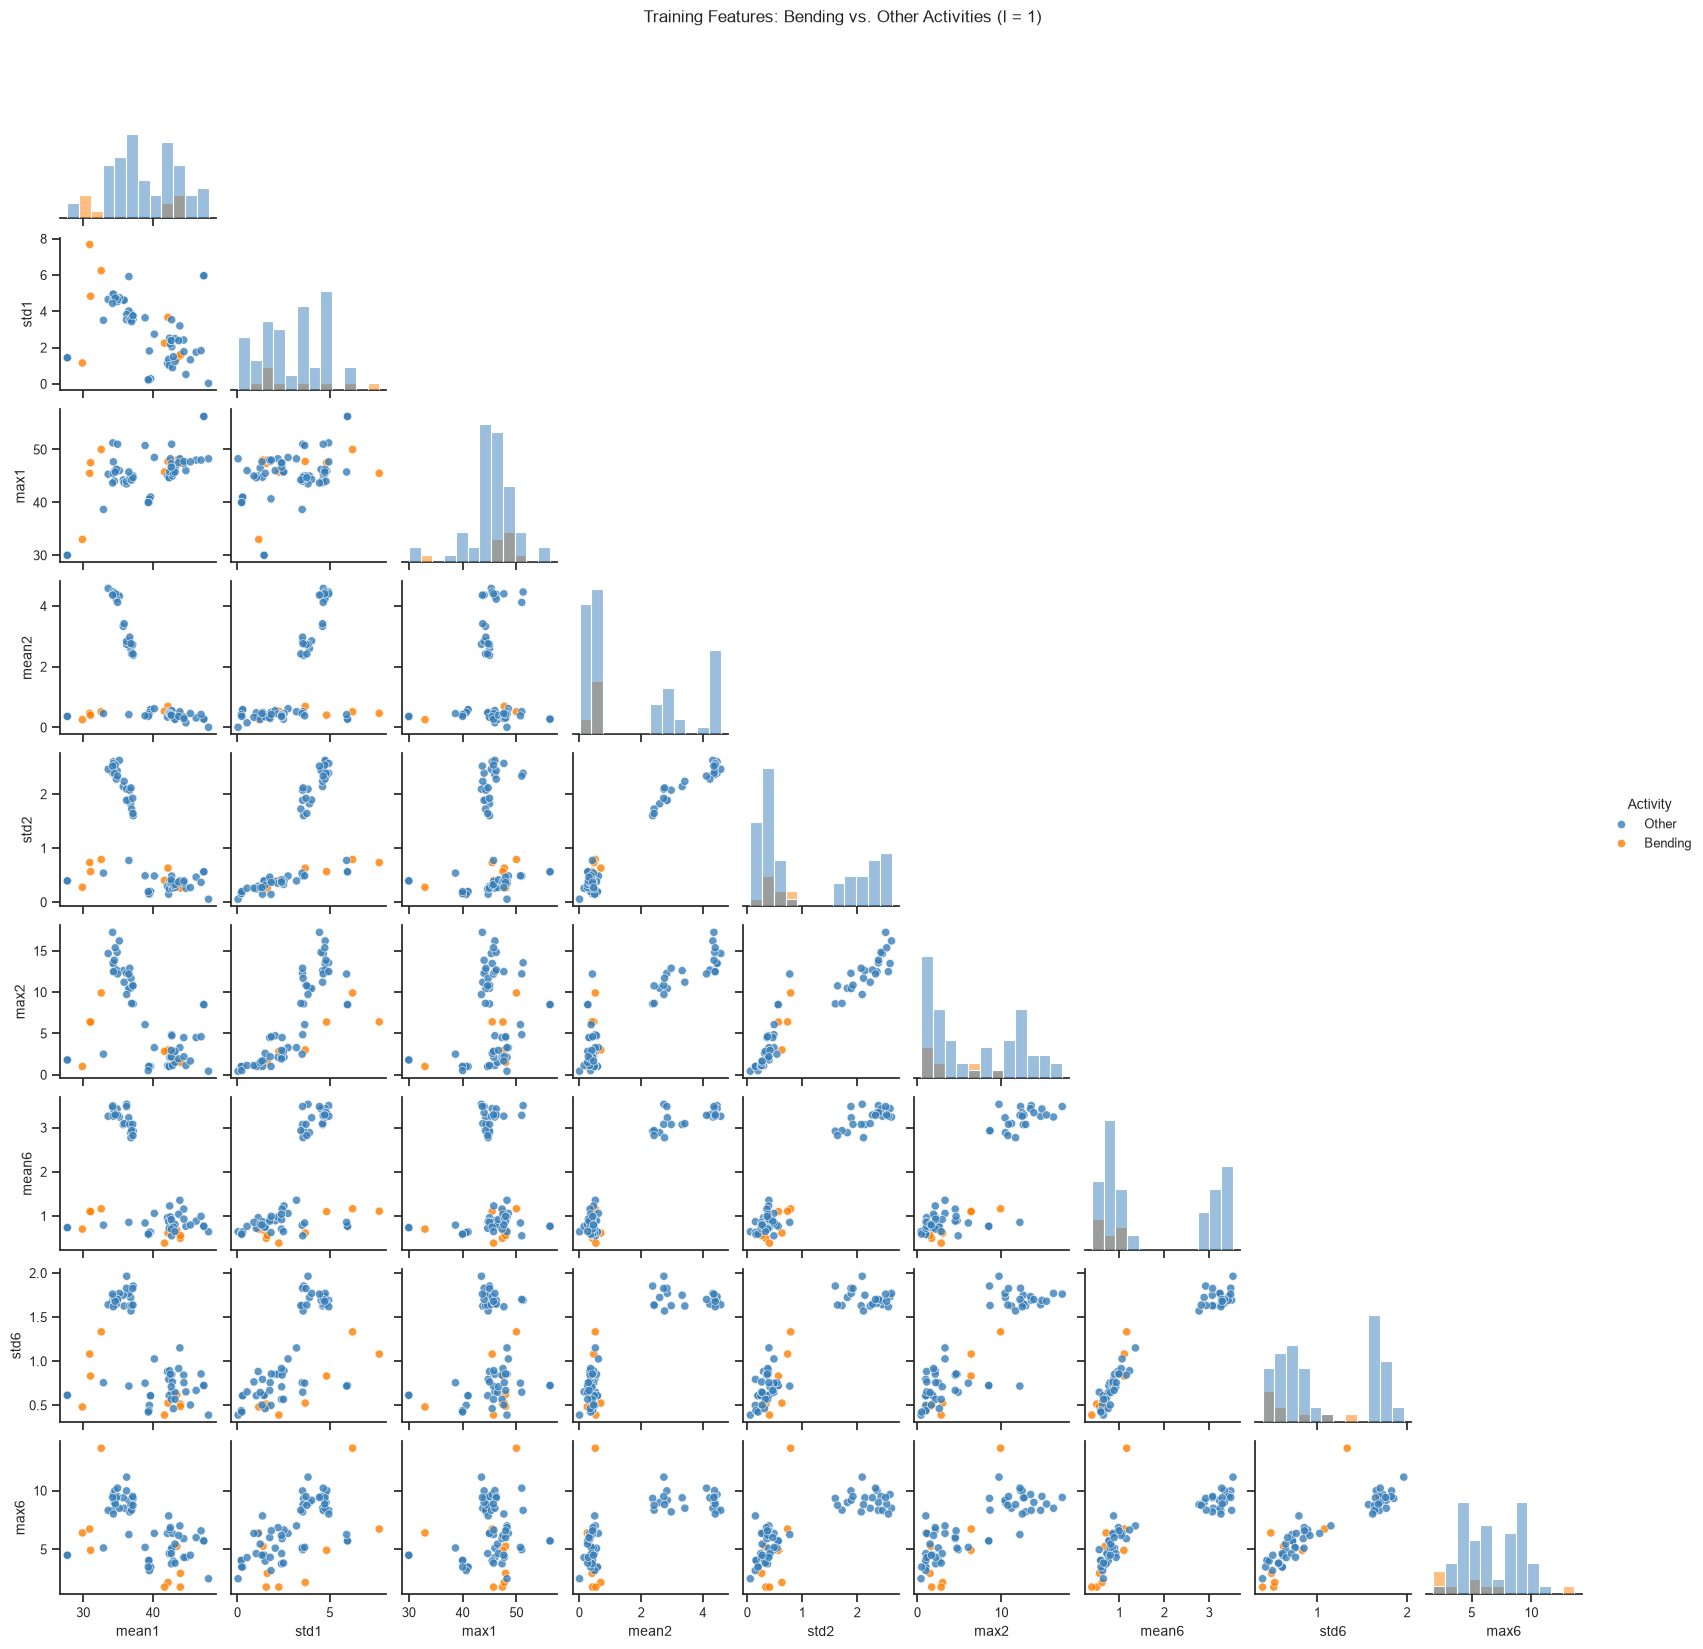

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks", font_scale=0.85)

activity_colors = {
    "Other": "#377EB8",
    "Bending": "#FF7F00"
}

g = sns.pairplot(
    data=plot_data_l1,
    vars=plot_columns,
    hue="Activity",
    hue_order=["Other", "Bending"],
    palette=activity_colors,
    diag_kind="hist",
    corner=True,
    height=1.8,
    plot_kws={
        "alpha": 0.8,
        "s": 35
    },
    diag_kws={
        "bins": 12,
        "alpha": 0.5
    }
)

g.figure.suptitle(
    "Training Features: Bending vs. Other Activities (l = 1)",
    y=1.02
)

plt.show()

The bending instances have low values of mean2 and mean6.
These features help separate bending from some other activities.

However, the two classes still overlap in several plots.
No single feature shown here clearly separates all bending instances
from all other instances.

#### (ii) Scatter Plots After Splitting Each Time Series

I split each time series into two parts of nearly equal length.
I keep the original time order.

I extract mean, standard deviation, and maximum from both parts
of time series 1, 2, and 6. This gives 18 features for the plots.

The training set still has 69 instances.

In [5]:
def extract_segment_features(df, n_segments):
    features = {}

    segments = np.array_split(np.arange(len(df)), n_segments)

    for part, row_positions in enumerate(segments, start=1):
        segment = df.iloc[row_positions]
        part_features = extract_features(segment)

        for name, value in part_features.items():
            features[f"{name}_part{part}"] = value

    return features


features_l2 = pd.DataFrame(
    [extract_segment_features(df, n_segments=2) for df in instances],
    index=metadata.index
)

X_train_l2 = features_l2.loc[train_mask].copy()

plot_columns_l2 = [
    f"{feature}{series}_part{part}"
    for part in [1, 2]
    for series in [1, 2, 6]
    for feature in ["mean", "std", "max"]
]

plot_data_l2 = X_train_l2[plot_columns_l2].copy()

plot_data_l2["Activity"] = metadata.loc[
    train_mask, "binary_label"
].map({0: "Other", 1: "Bending"})

print("Training feature table:", X_train_l2.shape)
print("Features used in plots:", len(plot_columns_l2))

display(plot_data_l2.head())

assert X_train_l2.shape == (69, 84)
assert plot_data_l2[plot_columns_l2].shape == (69, 18)
assert not plot_data_l2.isna().any().any()

Training feature table: (69, 84)
Features used in plots: 18


,mean1_part1,std1_part1,max1_part1,mean2_part1,std2_part1,max2_part1,mean6_part1,std6_part1,max6_part1,mean1_part2,std1_part2,max1_part2,mean2_part2,std2_part2,max2_part2,mean6_part2,std6_part2,max6_part2,Activity
2,44.057167,1.556971,46.50,0.381042,0.329540,1.50,0.598250,0.526656,1.79,43.851833,1.557168,47.40,0.471458,0.342346,1.70,0.388333,0.478528,1.50,Bending
3,43.278875,3.473355,47.75,0.673292,0.634285,3.00,0.640958,0.554542,1.53,41.080750,3.537481,46.00,0.718792,0.627915,2.86,0.586083,0.491873,2.18,Bending
4,41.621208,3.118644,45.75,0.623083,0.489595,2.83,0.419083,0.411200,1.79,41.734917,0.595920,43.67,0.448875,0.273050,1.12,0.347500,0.363144,1.50,Bending
5,44.117042,1.359836,48.00,0.250042,0.314099,1.30,0.815417,0.718016,5.26,42.792875,1.058792,46.50,0.506125,0.260761,1.58,0.543875,0.473445,4.06,Bending
6,43.486208,1.281976,45.00,0.378667,0.284434,1.30,0.524875,0.486847,2.28,44.452042,1.771251,48.00,0.447583,0.235493,1.50,0.585750,0.487918,2.96,Bending


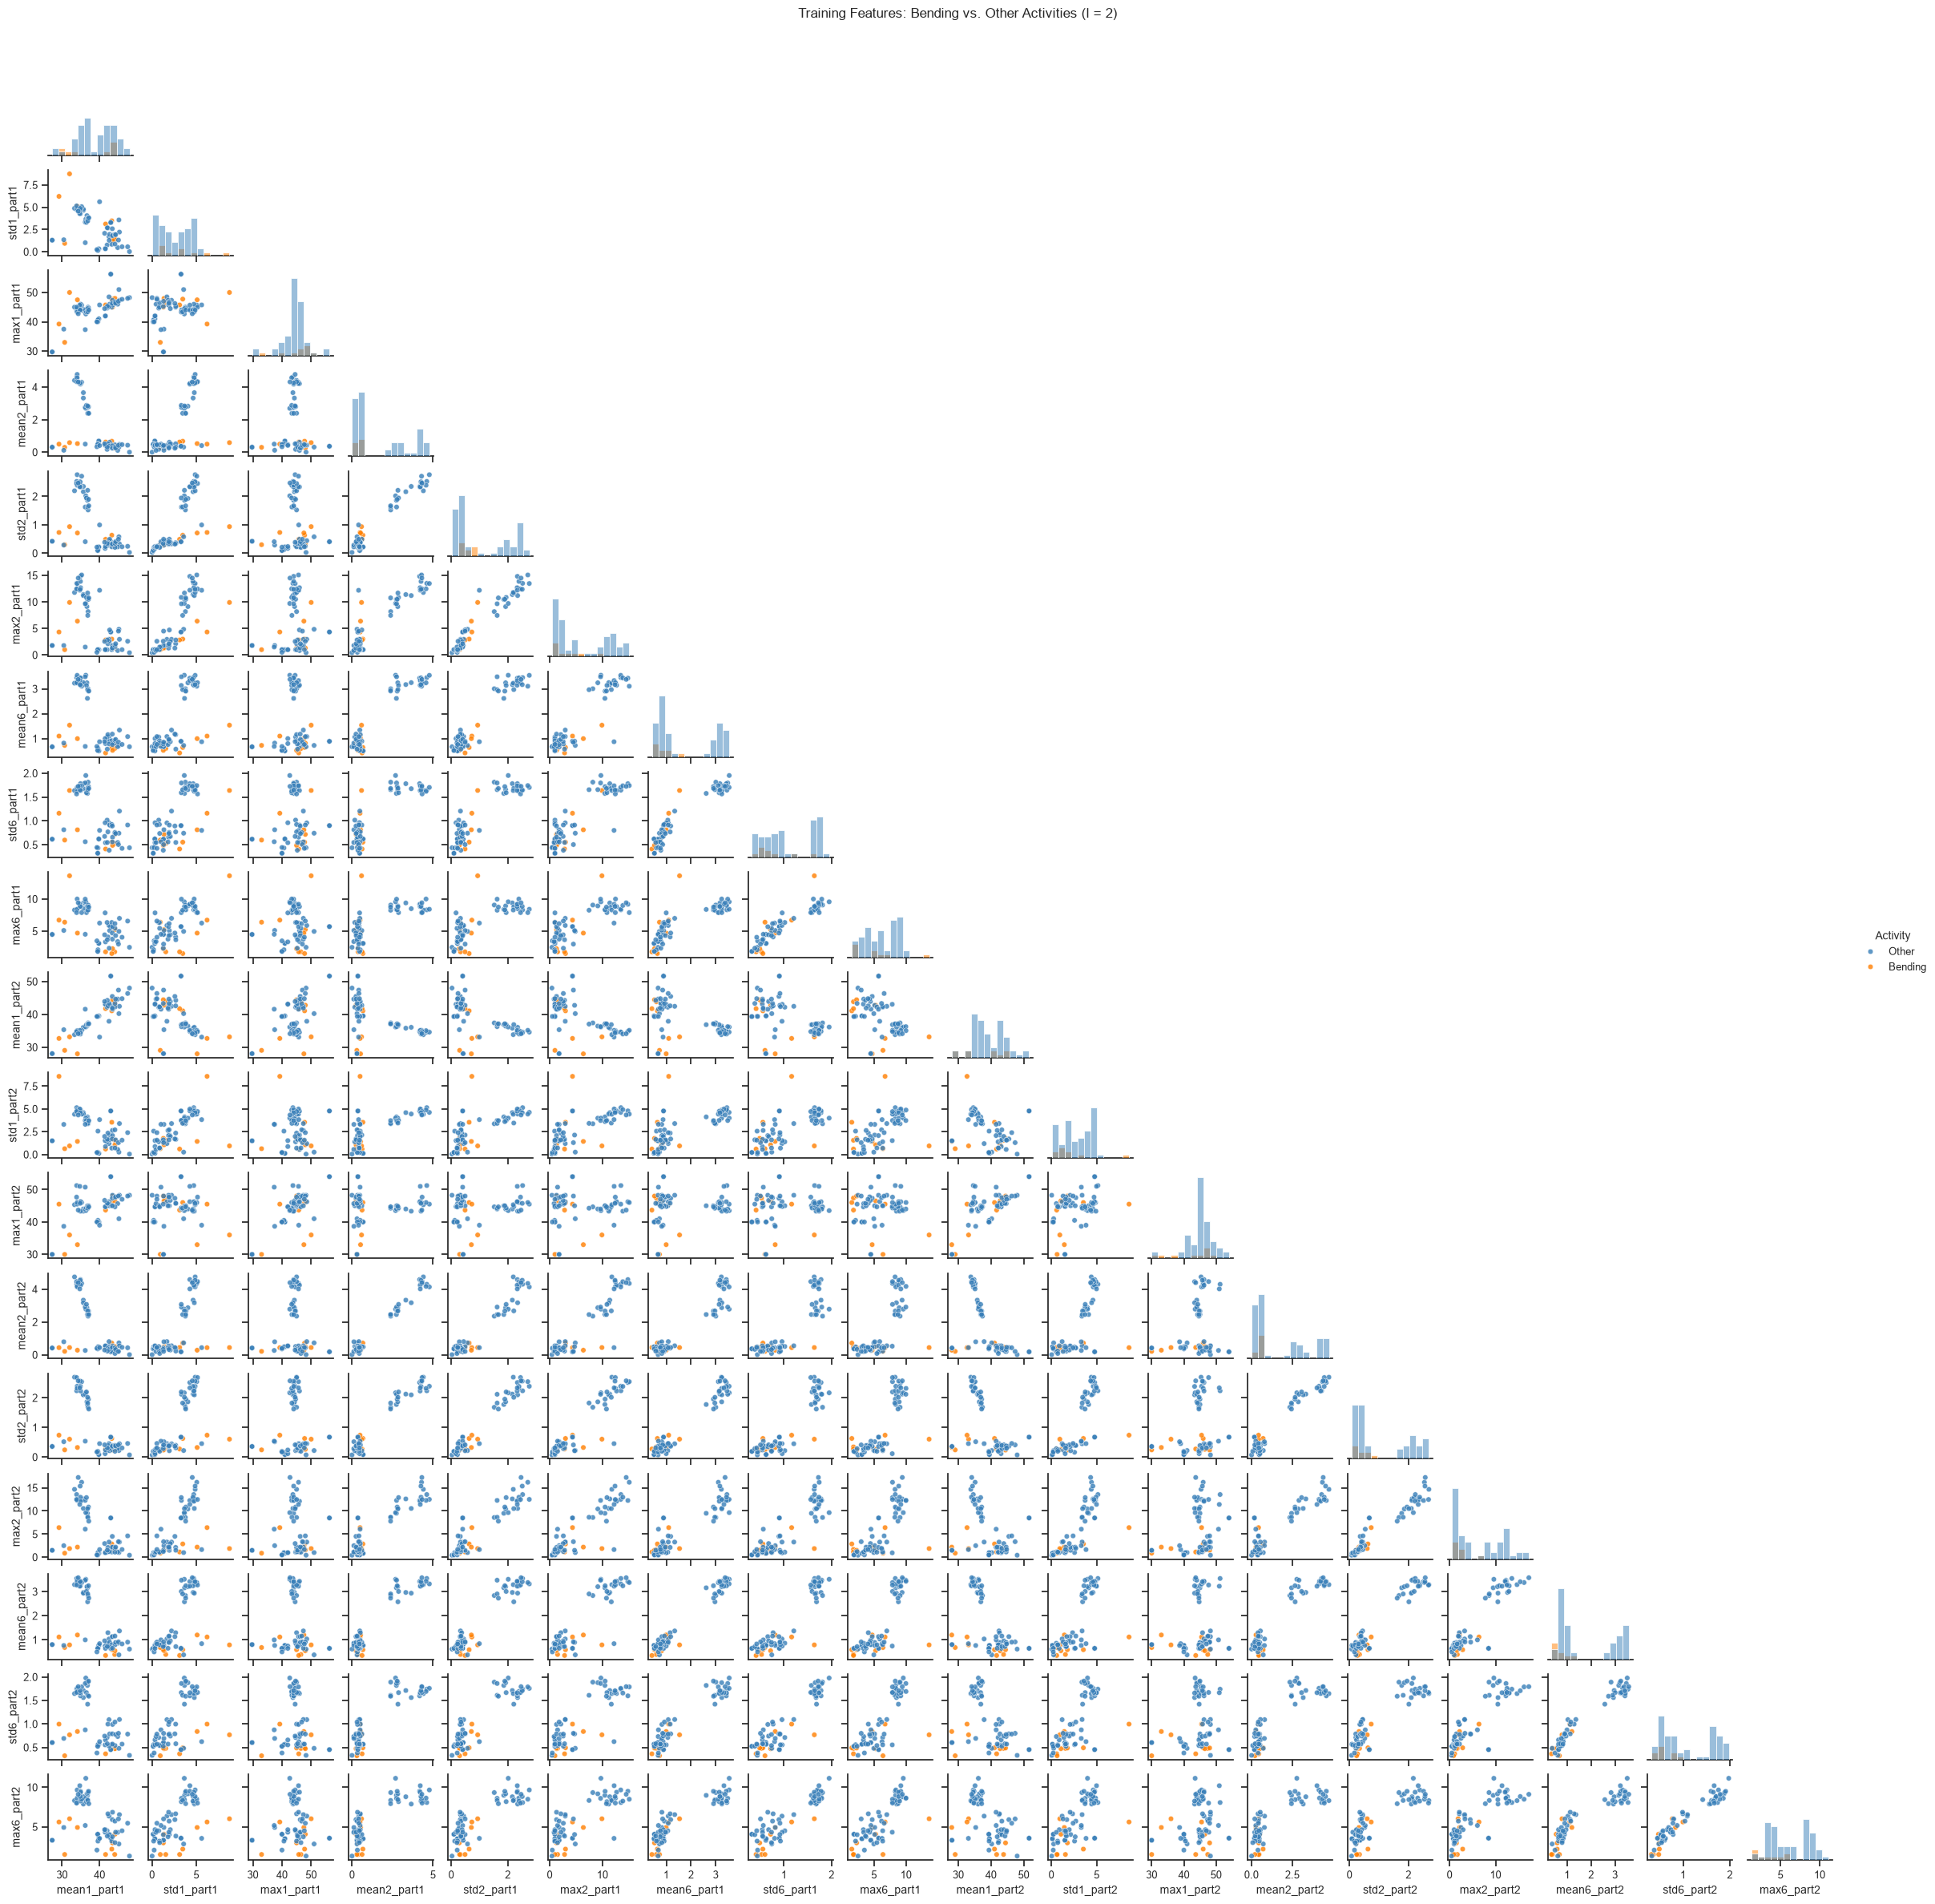

In [6]:
g2 = sns.pairplot(
    data=plot_data_l2,
    vars=plot_columns_l2,
    hue="Activity",
    hue_order=["Other", "Bending"],
    palette=activity_colors,
    diag_kind="hist",
    corner=True,
    height=1.3,
    plot_kws={
        "alpha": 0.8,
        "s": 22
    },
    diag_kws={
        "bins": 12,
        "alpha": 0.5
    }
)

g2.figure.suptitle(
    "Training Features: Bending vs. Other Activities (l = 2)",
    y=1.02
)

plt.show()

The overall pattern is similar to the plots before splitting.
Bending still has low mean values in time series 2 and 6.

Splitting changes some feature values, but the two classes still overlap.
I do not see a clear overall improvement in separation.
Cross-validation will help check whether splitting improves accuracy.

#### (iii) Choose the Number of Segments and Features

I use recursive feature elimination (RFE) to select features.
I use five-fold stratified cross-validation to choose l and p.

- l is the number of segments for each time series.
- p is the number of features kept by RFE.

Stratified cross-validation keeps the class proportions close
to those in the training set.

The right way is to fit scaling and feature selection using only
the training portion of each fold. The validation portion is used
to score the model.

The wrong way is to select features using all training instances
before cross-validation. This lets the validation data affect
feature selection and can make the score too optimistic.

I keep the test set out of model selection.

In [7]:
train_ids = metadata.index[train_mask].to_numpy()
train_instances = [instances[i] for i in train_ids]

train_features_by_l = {}

for l in range(1, 21):
    X = pd.DataFrame(
        [
            extract_segment_features(df, n_segments=l)
            for df in train_instances
        ],
        index=train_ids
    )

    assert X.shape == (69, 42 * l)
    assert np.isfinite(X.to_numpy()).all()

    train_features_by_l[l] = X

    print(f"l = {l:2d}: {X.shape[0]} instances, {X.shape[1]} features")

assert np.array_equal(
    metadata.loc[train_ids, "binary_label"].to_numpy(),
    y_train_binary
)

l =  1: 69 instances, 42 features
l =  2: 69 instances, 84 features
l =  3: 69 instances, 126 features
l =  4: 69 instances, 168 features
l =  5: 69 instances, 210 features
l =  6: 69 instances, 252 features
l =  7: 69 instances, 294 features
l =  8: 69 instances, 336 features
l =  9: 69 instances, 378 features
l = 10: 69 instances, 420 features
l = 11: 69 instances, 462 features
l = 12: 69 instances, 504 features
l = 13: 69 instances, 546 features
l = 14: 69 instances, 588 features
l = 15: 69 instances, 630 features
l = 16: 69 instances, 672 features
l = 17: 69 instances, 714 features
l = 18: 69 instances, 756 features
l = 19: 69 instances, 798 features
l = 20: 69 instances, 840 features


In [9]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(
    cv.split(
        np.zeros((len(y_train_binary), 1)),
        y_train_binary
    )
)

fold_records = []

for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    y_fit = y_train_binary[fit_idx]
    y_valid = y_train_binary[valid_idx]

    fold_records.append({
        "fold": fold,
        "fit_other": int((y_fit == 0).sum()),
        "fit_bending": int((y_fit == 1).sum()),
        "valid_other": int((y_valid == 0).sum()),
        "valid_bending": int((y_valid == 1).sum())
    })

fold_table = pd.DataFrame(fold_records)

display(fold_table)

assert (fold_table["fit_bending"] > 0).all()
assert (fold_table["valid_bending"] > 0).all()

,fold,fit_other,fit_bending,valid_other,valid_bending
0,1,48,7,12,2
1,2,48,7,12,2
2,3,48,7,12,2
3,4,48,7,12,2
4,5,48,8,12,1


##### Run Logistic Regression with RFE

I test l values from 1 to 20.
For each l, RFE removes one feature at a time.
I use five-fold cross-validation to choose how many features to keep.

StandardScaler is inside the model pipeline.
It learns the mean and standard deviation only from the training
portion of each fold.

I use logistic regression without regularization.
I choose the pair with the highest mean validation accuracy.
If scores are tied, I choose fewer features, then fewer segments.

In [10]:
from time import perf_counter

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from threadpoolctl import threadpool_limits

base_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            C=np.inf,
            solver="lbfgs",
            max_iter=2000,
            tol=1e-4
        )
    )
])

rfe_models_by_l = {}
rfe_cv_results_by_l = {}
rfe_records = []

start_time = perf_counter()

with threadpool_limits(limits=1):
    for l in range(1, 21):
        X = train_features_by_l[l]

        selector = RFECV(
            estimator=base_model,
            step=1,
            min_features_to_select=1,
            cv=cv_splits,
            scoring="accuracy",
            n_jobs=1,
            importance_getter="named_steps.logistic.coef_"
        )

        selector.fit(X, y_train_binary)

        # Keep the score for every feature count.
        cv_table = pd.DataFrame({
            "p": selector.cv_results_["n_features"],
            "cv_accuracy": selector.cv_results_["mean_test_score"],
            "cv_std": selector.cv_results_["std_test_score"]
        })

        best_p = int(selector.n_features_)
        best_result = cv_table.loc[
            cv_table["p"].eq(best_p)
        ].iloc[0]

        rfe_models_by_l[l] = selector
        rfe_cv_results_by_l[l] = cv_table

        rfe_records.append({
            "l": l,
            "total_features": X.shape[1],
            "best_p": best_p,
            "cv_accuracy": float(best_result["cv_accuracy"]),
            "cv_std": float(best_result["cv_std"])
        })

        elapsed = perf_counter() - start_time

        print(
            f"l = {l:2d} | "
            f"best p = {best_p:3d} | "
            f"CV accuracy = {best_result['cv_accuracy']:.4f} | "
            f"elapsed = {elapsed:.1f}s",
            flush=True
        )

rfe_summary = (
    pd.DataFrame(rfe_records)
    .sort_values(
        ["cv_accuracy", "best_p", "l"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

print("\nBest result for each l:")
display(rfe_summary)

l =  1 | best p =  16 | CV accuracy = 0.9857 | elapsed = 0.5s
l =  2 | best p =   6 | CV accuracy = 0.9714 | elapsed = 1.5s
l =  3 | best p =   6 | CV accuracy = 0.9429 | elapsed = 2.9s
l =  4 | best p =   9 | CV accuracy = 0.9571 | elapsed = 5.0s
l =  5 | best p =   1 | CV accuracy = 0.9571 | elapsed = 7.5s
l =  6 | best p =   5 | CV accuracy = 0.9571 | elapsed = 10.6s
l =  7 | best p =   8 | CV accuracy = 0.9571 | elapsed = 14.2s
l =  8 | best p =   2 | CV accuracy = 0.9429 | elapsed = 18.4s
l =  9 | best p =  10 | CV accuracy = 0.9571 | elapsed = 23.2s
l = 10 | best p =   8 | CV accuracy = 0.9857 | elapsed = 28.5s
l = 11 | best p =   1 | CV accuracy = 0.9571 | elapsed = 34.5s
l = 12 | best p =   2 | CV accuracy = 0.9714 | elapsed = 41.1s
l = 13 | best p =  13 | CV accuracy = 0.9571 | elapsed = 48.4s
l = 14 | best p =  12 | CV accuracy = 0.9429 | elapsed = 56.5s
l = 15 | best p =  28 | CV accuracy = 0.9571 | elapsed = 65.2s
l = 16 | best p =  12 | CV accuracy = 0.9286 | elapsed = 74.

,l,total_features,best_p,cv_accuracy,cv_std
0,19,798,7,0.985714,0.028571
1,10,420,8,0.985714,0.028571
2,1,42,16,0.985714,0.028571
3,17,714,1,0.971429,0.034993
4,12,504,2,0.971429,0.034993
5,20,840,4,0.971429,0.034993
6,2,84,6,0.971429,0.034993
7,5,210,1,0.957143,0.034993
8,11,462,1,0.957143,0.034993
9,6,252,5,0.957143,0.034993


In [11]:
best_result_rfe = rfe_summary.iloc[0]

best_l_rfe = int(best_result_rfe["l"])
best_p_rfe = int(best_result_rfe["best_p"])
best_cv_accuracy_rfe = float(best_result_rfe["cv_accuracy"])

best_rfe_model = rfe_models_by_l[best_l_rfe]

X_train_best_rfe = train_features_by_l[best_l_rfe]

selected_features_rfe = X_train_best_rfe.columns[
    best_rfe_model.support_
].tolist()

print("Best number of segments (l):", best_l_rfe)
print("Selected feature count (p):", best_p_rfe)
print(f"Mean CV accuracy: {best_cv_accuracy_rfe:.4f}")

print("\nSelected features:")
display(pd.DataFrame({
    "feature": selected_features_rfe
}))

assert len(selected_features_rfe) == best_p_rfe

Best number of segments (l): 19
Selected feature count (p): 7
Mean CV accuracy: 0.9857

Selected features:


,feature
0,min5_part3
1,mean5_part3
2,q1_5_part3
3,q3_1_part12
4,std3_part15
5,min5_part17
6,std5_part18


The selected model uses 19 segments and keeps 7 features.
Its mean five-fold validation accuracy is 0.9857.

The best models for l = 1, 10, and 19 have the same validation accuracy.
I choose l = 19 because it keeps the fewest features among these models.
The test set has not been used to choose the model.

#### (iv) Training Results and Model Parameters

I report the confusion matrix, ROC curve, and AUC on the training set.
Bending is the positive class.

These results show how well the model fits the training data.
They do not measure its performance on new data.

Training accuracy: 1.0000
Training AUC: 1.0000


,Predicted Other,Predicted Bending
Actual Other,60,0
Actual Bending,0,9


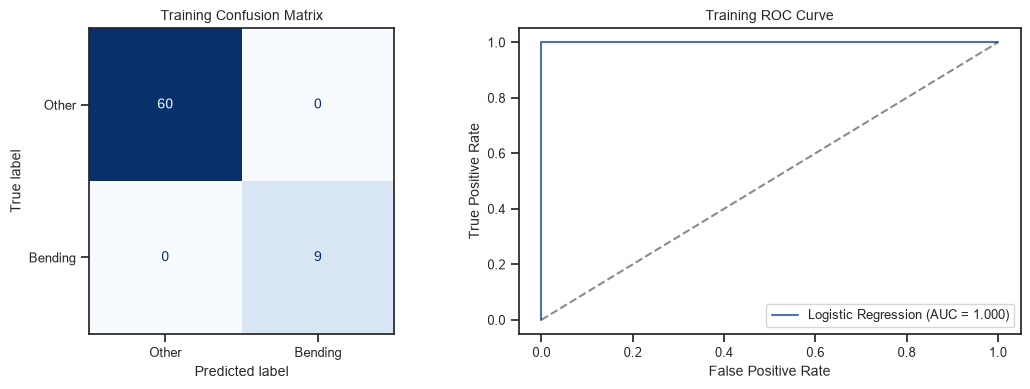

In [12]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

train_pred_rfe = best_rfe_model.predict(X_train_best_rfe)

positive_index = np.flatnonzero(
    best_rfe_model.classes_ == 1
)[0]

train_prob_rfe = best_rfe_model.predict_proba(
    X_train_best_rfe
)[:, positive_index]

train_accuracy_rfe = accuracy_score(
    y_train_binary, train_pred_rfe
)

train_auc_rfe = roc_auc_score(
    y_train_binary, train_prob_rfe
)

train_cm_rfe = confusion_matrix(
    y_train_binary,
    train_pred_rfe,
    labels=[0, 1]
)

print(f"Training accuracy: {train_accuracy_rfe:.4f}")
print(f"Training AUC: {train_auc_rfe:.4f}")

display(pd.DataFrame(
    train_cm_rfe,
    index=["Actual Other", "Actual Bending"],
    columns=["Predicted Other", "Predicted Bending"]
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix=train_cm_rfe,
    display_labels=["Other", "Bending"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Training Confusion Matrix")

fpr, tpr, thresholds = roc_curve(
    y_train_binary, train_prob_rfe
)

axes[1].plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {train_auc_rfe:.3f})"
)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Training ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [13]:
fitted_pipeline_rfe = best_rfe_model.estimator_

scaler_rfe = fitted_pipeline_rfe.named_steps["scale"]
logistic_rfe = fitted_pipeline_rfe.named_steps["logistic"]

beta_scaled_rfe = logistic_rfe.coef_[0]
intercept_scaled_rfe = logistic_rfe.intercept_[0]

beta_original_rfe = beta_scaled_rfe / scaler_rfe.scale_

intercept_original_rfe = (
    intercept_scaled_rfe
    - np.dot(beta_original_rfe, scaler_rfe.mean_)
)

coefficient_table_rfe = pd.DataFrame({
    "term": ["Intercept"] + selected_features_rfe,
    "coefficient_standardized": np.r_[
        intercept_scaled_rfe, beta_scaled_rfe
    ],
    "coefficient_original": np.r_[
        intercept_original_rfe, beta_original_rfe
    ]
})

train_scores_rfe = best_rfe_model.decision_function(
    X_train_best_rfe
)

signed_scores_rfe = (
    2 * y_train_binary - 1
) * train_scores_rfe

complete_separation_rfe = bool(
    np.all(signed_scores_rfe > 0)
)

print("Complete separation:", complete_separation_rfe)
print(f"Smallest signed score: {signed_scores_rfe.min():.4f}")

if complete_separation_rfe:
    coefficient_table_rfe["p_value"] = np.nan
    print(
        "Wald p-values are unavailable because complete separation "
        "prevents a finite maximum likelihood estimate."
    )

display(coefficient_table_rfe)

Complete separation: True
Smallest signed score: 6.3065
Wald p-values are unavailable because complete separation prevents a finite maximum likelihood estimate.


,term,coefficient_standardized,coefficient_original,p_value
0,Intercept,-10.493238,-7.624039,NaN
1,min5_part3,2.757989,0.407920,NaN
2,mean5_part3,2.608423,0.406119,NaN
3,q1_5_part3,4.006500,0.622281,NaN
4,q3_1_part12,-2.171958,-0.432112,NaN
5,std3_part15,-2.422409,-2.241767,NaN
6,min5_part17,2.453601,0.382895,NaN
7,std5_part18,-1.487598,-1.306045,NaN


The model correctly classifies all 69 training instances.
The training accuracy and AUC are both 1.0.

All signed scores are positive, so the selected features allow
complete separation of the training classes.

With complete separation, unpenalized logistic regression has
no finite maximum likelihood estimate. The coefficients shown
are the numerical values returned when the solver stopped.

The usual Wald p-values are not valid here, so I report them as N/A.
A perfect training result does not guarantee perfect test results.

#### (v) Test Results

I split each test time series into 19 segments.
I extract the same features in the same order as the training set.

I use the fitted model to make predictions.
I do not fit the scaler or select features again.
I compare the test accuracy with the mean cross-validation accuracy.

In [14]:
test_ids = metadata.index[test_mask].to_numpy()
test_instances = [instances[i] for i in test_ids]

X_test_best_rfe = pd.DataFrame(
    [
        extract_segment_features(df, n_segments=best_l_rfe)
        for df in test_instances
    ],
    index=test_ids
)

X_test_best_rfe = X_test_best_rfe.loc[
    :, X_train_best_rfe.columns
]

assert X_test_best_rfe.shape == (19, 42 * best_l_rfe)
assert np.isfinite(X_test_best_rfe.to_numpy()).all()

assert np.array_equal(
    metadata.loc[test_ids, "binary_label"].to_numpy(),
    y_test_binary
)

test_pred_rfe = best_rfe_model.predict(X_test_best_rfe)

test_prob_rfe = best_rfe_model.predict_proba(
    X_test_best_rfe
)[:, positive_index]

test_accuracy_rfe = accuracy_score(
    y_test_binary, test_pred_rfe
)

test_auc_rfe = roc_auc_score(
    y_test_binary, test_prob_rfe
)

test_cm_rfe = confusion_matrix(
    y_test_binary,
    test_pred_rfe,
    labels=[0, 1]
)

print("Test feature table:", X_test_best_rfe.shape)
print("Features used by the model:", best_p_rfe)
print(f"Mean CV accuracy: {best_cv_accuracy_rfe:.4f}")
print(f"Test accuracy: {test_accuracy_rfe:.4f}")
print(f"Test error: {1 - test_accuracy_rfe:.4f}")
print(f"Test AUC: {test_auc_rfe:.4f}")

print(
    "Test minus CV accuracy: "
    f"{100 * (test_accuracy_rfe - best_cv_accuracy_rfe):+.2f} "
    "percentage points"
)

display(pd.DataFrame(
    test_cm_rfe,
    index=["Actual Other", "Actual Bending"],
    columns=["Predicted Other", "Predicted Bending"]
))

Test feature table: (19, 798)
Features used by the model: 7
Mean CV accuracy: 0.9857
Test accuracy: 0.9474
Test error: 0.0526
Test AUC: 0.9000
Test minus CV accuracy: -3.83 percentage points


,Predicted Other,Predicted Bending
Actual Other,15,0
Actual Bending,1,3


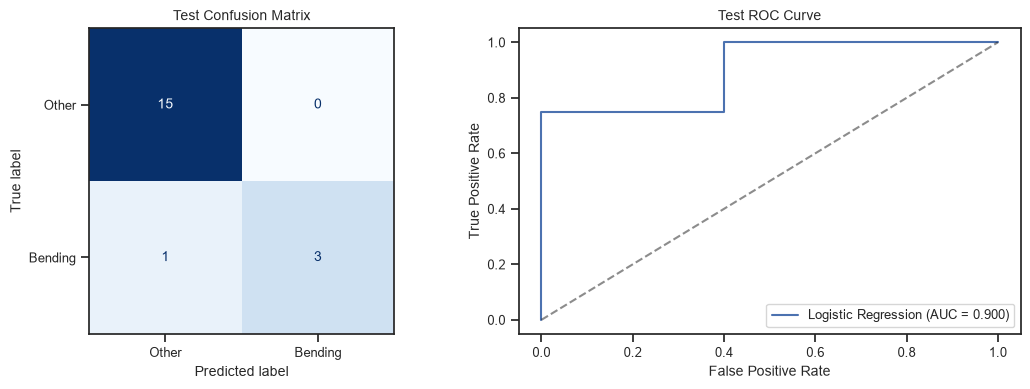

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm_rfe,
    display_labels=["Other", "Bending"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Test Confusion Matrix")

test_fpr, test_tpr, test_thresholds = roc_curve(
    y_test_binary, test_prob_rfe
)

axes[1].plot(
    test_fpr,
    test_tpr,
    label=f"Logistic Regression (AUC = {test_auc_rfe:.3f})"
)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Test ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [16]:
test_predictions_rfe = metadata.loc[
    test_ids, ["activity", "filename"]
].copy()

test_predictions_rfe["actual_label"] = y_test_binary
test_predictions_rfe["predicted_label"] = test_pred_rfe
test_predictions_rfe["bending_probability"] = test_prob_rfe

test_predictions_rfe["correct"] = (
    test_predictions_rfe["actual_label"]
    == test_predictions_rfe["predicted_label"]
)

print("Misclassified test instances:")

mistakes_rfe = test_predictions_rfe.loc[
    ~test_predictions_rfe["correct"]
]

if mistakes_rfe.empty:
    print("None")
else:
    display(mistakes_rfe)

Misclassified test instances:


,activity,filename,actual_label,predicted_label,bending_probability,correct
8,bending2,dataset2.csv,1,0,0.000057,False


The test accuracy is 0.9474, compared with a mean CV accuracy of 0.9857.
The test accuracy is about 3.83 percentage points lower.

The model correctly predicts 18 of the 19 test instances.
It correctly identifies all 15 other activities and 3 of the 4 bending
instances. The bending recall is 0.75, and the test AUC is 0.90.

The only mistake is bending2/dataset2.csv, which is predicted as Other.
The test set is small, so one mistake changes accuracy by about
5.26 percentage points.

#### (vi) Class Separation and Parameter Stability

Yes. The selected features completely separate the training classes.
All training instances have positive signed scores.

With complete separation, the coefficient values can keep growing
while the likelihood improves. There is no finite maximum likelihood
estimate for the unpenalized model.

The solver returns finite values because it stops at a numerical
tolerance. These values can change with the stopping settings.
The usual Wald p-values are not valid in this case.

#### (vii) Class Imbalance and Case-Control Sampling

The training set contains 60 Other instances and 9 Bending instances.
The classes are imbalanced.

I keep all 9 Bending instances and randomly select 9 Other instances
without replacement. This gives a balanced sample of 18 instances.
I use random seed 42.

I keep the selected 19 segments and 7 features.
I fit a new logistic regression model on the sampled training data.

I adjust the intercept using the original training class proportions.
The adjustment is log(9/60) - log(9/9), which is about -1.8971.
The test labels are not used for this adjustment.

This adjustment accounts for the changed class proportions.
It does not solve complete separation.

In [17]:
X_train_selected_rfe = X_train_best_rfe[
    selected_features_rfe
].copy()

X_test_selected_rfe = X_test_best_rfe[
    selected_features_rfe
].copy()

rng_cc = np.random.default_rng(42)

case_positions = np.flatnonzero(y_train_binary == 1)
control_positions = np.flatnonzero(y_train_binary == 0)

sampled_control_positions = rng_cc.choice(
    control_positions,
    size=len(case_positions),
    replace=False
)

cc_positions = np.sort(np.concatenate([
    case_positions,
    sampled_control_positions
]))

X_cc = X_train_selected_rfe.iloc[cc_positions]
y_cc = y_train_binary[cc_positions]

print("Sampled Other instances:", int((y_cc == 0).sum()))
print("Sampled Bending instances:", int((y_cc == 1).sum()))

cc_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            C=np.inf,
            solver="lbfgs",
            max_iter=2000,
            tol=1e-4
        )
    )
])

with threadpool_limits(limits=1):
    cc_model.fit(X_cc, y_cc)

cc_signed_scores = (
    2 * y_cc - 1
) * cc_model.decision_function(X_cc)

cc_complete_separation = bool(np.all(cc_signed_scores > 0))

original_share = y_train_binary.mean()
sampled_share = y_cc.mean()

cc_intercept_adjustment = (
    np.log(original_share / (1 - original_share))
    - np.log(sampled_share / (1 - sampled_share))
)

cc_logistic = cc_model.named_steps["logistic"]
cc_intercept_before = float(cc_logistic.intercept_[0])

cc_logistic.intercept_ = np.array([
    cc_intercept_before + cc_intercept_adjustment
])

print(
    "Complete separation in the sampled data:",
    cc_complete_separation
)
print(f"Intercept adjustment: {cc_intercept_adjustment:.4f}")
print(f"Intercept before adjustment: {cc_intercept_before:.4f}")
print(f"Intercept after adjustment: {cc_logistic.intercept_[0]:.4f}")

Sampled Other instances: 9
Sampled Bending instances: 9
Complete separation in the sampled data: True
Intercept adjustment: -1.8971
Intercept before adjustment: 1.8924
Intercept after adjustment: -0.0047


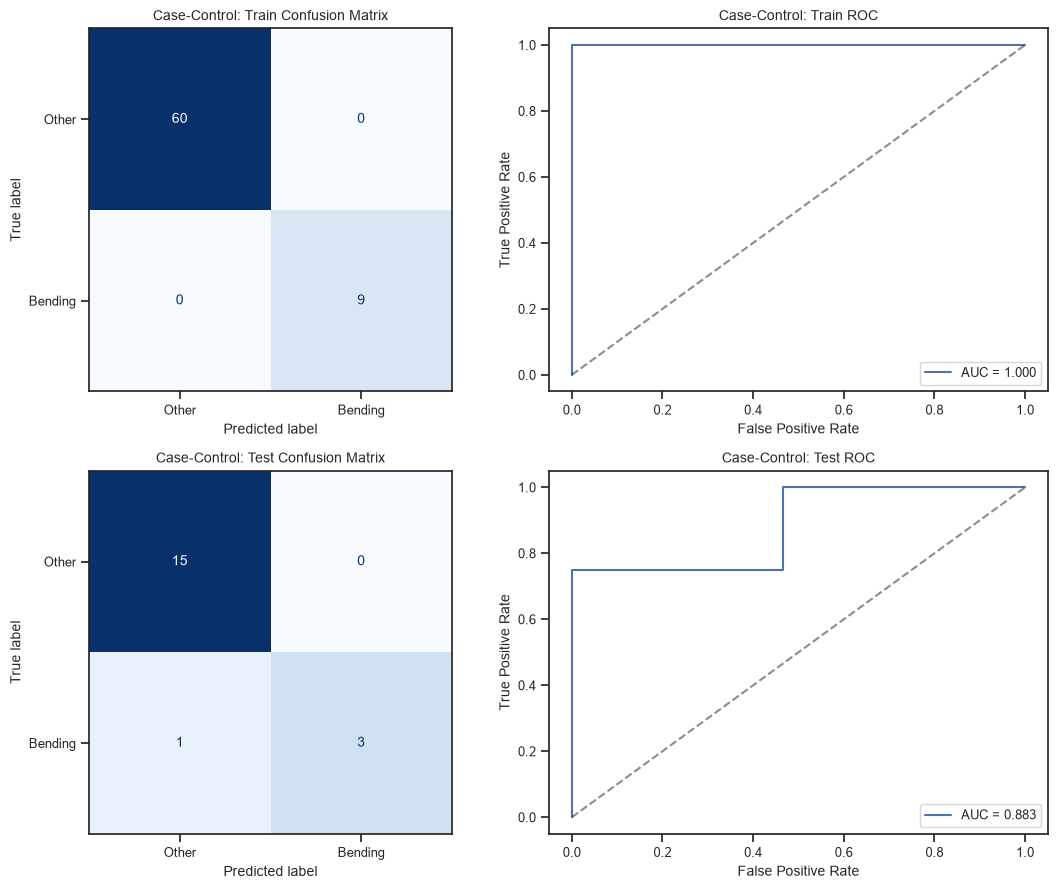

,split,accuracy,bending_recall,AUC
0,Train,1.000000,1.00,1.000000
1,Test,0.947368,0.75,0.883333


In [18]:
cc_records = []
cc_results = {}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

evaluation_sets = [
    ("Train", X_train_selected_rfe, y_train_binary),
    ("Test", X_test_selected_rfe, y_test_binary)
]

for row, (split_name, X_eval, y_eval) in enumerate(evaluation_sets):
    predictions = cc_model.predict(X_eval)
    scores = cc_model.decision_function(X_eval)

    cm = confusion_matrix(y_eval, predictions, labels=[0, 1])
    accuracy = accuracy_score(y_eval, predictions)
    auc = roc_auc_score(y_eval, scores)
    bending_recall = cm[1, 1] / cm[1].sum()

    cc_records.append({
        "split": split_name,
        "accuracy": accuracy,
        "bending_recall": bending_recall,
        "AUC": auc
    })

    cc_results[split_name] = {
        "confusion_matrix": cm,
        "predictions": predictions,
        "scores": scores
    }

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Other", "Bending"]
    ).plot(
        ax=axes[row, 0],
        cmap="Blues",
        colorbar=False
    )

    axes[row, 0].set_title(
        f"Case-Control: {split_name} Confusion Matrix"
    )

    fpr_cc, tpr_cc, _ = roc_curve(y_eval, scores)

    axes[row, 1].plot(
        fpr_cc, tpr_cc,
        label=f"AUC = {auc:.3f}"
    )
    axes[row, 1].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[row, 1].set_xlabel("False Positive Rate")
    axes[row, 1].set_ylabel("True Positive Rate")
    axes[row, 1].set_title(
        f"Case-Control: {split_name} ROC"
    )
    axes[row, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

cc_summary = pd.DataFrame(cc_records)
display(cc_summary)

After case-control sampling and intercept adjustment, the test accuracy
is 0.9474 and the bending recall is 0.75.

These values are the same as those of the original model.
The test AUC drops from 0.9000 to 0.8833.
Case-control sampling does not improve test performance in this run.

The sampled data still have complete separation.
The intercept adjustment does not fix this problem.
The fitted coefficients and probabilities may still depend on
the solver's stopping settings.

### (b) Binary Classification Using L1-Penalized Logistic Regression

#### (i) Choose the Number of Segments and Regularization Strength

I use all 69 training instances.
I use all seven time-domain feature types from all six time series.

L1 regularization can set some coefficients to zero.
This selects features while fitting the model.

I test l values from 1 to 20 and 13 C values from 0.001 to 1000.
A smaller C gives stronger regularization.

I use the same five stratified folds as before.
Scaling is fitted inside each fold through a pipeline.

I choose the pair with the highest mean validation accuracy.
If scores are tied, I choose fewer segments, then a smaller C.
The test set is not used to choose these values.

In [19]:
from sklearn.model_selection import GridSearchCV

C_values = np.logspace(-3, 3, 13)

print("Candidate C values:")
print(C_values)

l1_pipeline = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            l1_ratio=1,
            solver="liblinear",
            max_iter=10000,
            tol=1e-4,
            random_state=42
        )
    )
])

l1_models_by_l = {}
l1_cv_results_by_l = {}
l1_records = []

start_time_l1 = perf_counter()

with threadpool_limits(limits=1):
    for l in range(1, 21):
        X = train_features_by_l[l]

        search = GridSearchCV(
            estimator=l1_pipeline,
            param_grid={"logistic__C": C_values},
            scoring="accuracy",
            cv=cv_splits,
            refit=True,
            n_jobs=1,
            error_score="raise"
        )

        search.fit(X, y_train_binary)

        best_model_for_l = search.best_estimator_
        best_C_for_l = float(search.best_params_["logistic__C"])

        coefficients = (
            best_model_for_l.named_steps["logistic"].coef_[0]
        )
        nonzero_count = int(np.count_nonzero(coefficients))

        l1_models_by_l[l] = best_model_for_l

        l1_cv_results_by_l[l] = pd.DataFrame({
            "C": [
                float(value)
                for value in search.cv_results_["param_logistic__C"]
            ],
            "cv_accuracy": search.cv_results_["mean_test_score"],
            "cv_std": search.cv_results_["std_test_score"]
        })

        l1_records.append({
            "l": l,
            "best_C": best_C_for_l,
            "cv_accuracy": float(search.best_score_),
            "cv_std": float(
                search.cv_results_["std_test_score"][search.best_index_]
            ),
            "nonzero_features": nonzero_count
        })

        elapsed = perf_counter() - start_time_l1

        print(
            f"l = {l:2d} | "
            f"best C = {best_C_for_l:.4g} | "
            f"CV accuracy = {search.best_score_:.4f} | "
            f"nonzero features = {nonzero_count} | "
            f"elapsed = {elapsed:.1f}s",
            flush=True
        )

l1_summary = (
    pd.DataFrame(l1_records)
    .sort_values(
        ["cv_accuracy", "l", "best_C"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

display(l1_summary)

Candidate C values:
[1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00
 1.00000000e+01 3.16227766e+01 1.00000000e+02 3.16227766e+02
 1.00000000e+03]
l =  1 | best C = 3.162 | CV accuracy = 0.9714 | nonzero features = 8 | elapsed = 0.2s
l =  2 | best C = 10 | CV accuracy = 0.9714 | nonzero features = 10 | elapsed = 0.5s
l =  3 | best C = 0.3162 | CV accuracy = 0.9571 | nonzero features = 5 | elapsed = 0.7s
l =  4 | best C = 316.2 | CV accuracy = 0.9571 | nonzero features = 28 | elapsed = 1.0s
l =  5 | best C = 31.62 | CV accuracy = 0.9418 | nonzero features = 19 | elapsed = 1.3s
l =  6 | best C = 10 | CV accuracy = 0.9571 | nonzero features = 17 | elapsed = 1.5s
l =  7 | best C = 31.62 | CV accuracy = 0.9560 | nonzero features = 20 | elapsed = 1.8s
l =  8 | best C = 100 | CV accuracy = 0.9429 | nonzero features = 26 | elapsed = 2.2s
l =  9 | best C = 3.162 | CV accuracy = 0.9418 | nonzero features = 14 | elapsed = 2.

,l,best_C,cv_accuracy,cv_std,nonzero_features
0,1,3.162278,0.971429,0.034993,8
1,2,10.000000,0.971429,0.034993,10
2,10,100.000000,0.971429,0.034993,30
3,12,1.000000,0.971429,0.034993,7
4,20,3.162278,0.971429,0.034993,12
5,3,0.316228,0.957143,0.057143,5
6,4,316.227766,0.957143,0.034993,28
7,6,10.000000,0.957143,0.034993,17
8,11,1.000000,0.957143,0.034993,8
9,13,1.000000,0.957143,0.034993,11


In [20]:
best_result_l1 = l1_summary.iloc[0]

best_l_l1 = int(best_result_l1["l"])
best_C_l1 = float(best_result_l1["best_C"])
best_cv_accuracy_l1 = float(best_result_l1["cv_accuracy"])

best_l1_model = l1_models_by_l[best_l_l1]
X_train_best_l1 = train_features_by_l[best_l_l1]

l1_coefficients = best_l1_model.named_steps["logistic"].coef_[0]
l1_nonzero_mask = l1_coefficients != 0

selected_features_l1 = X_train_best_l1.columns[
    l1_nonzero_mask
].tolist()

l1_coefficient_table = pd.DataFrame({
    "feature": selected_features_l1,
    "coefficient_standardized": l1_coefficients[l1_nonzero_mask]
})

print("Best number of segments (l):", best_l_l1)
print(f"Best C: {best_C_l1:.6g}")
print(f"Mean CV accuracy: {best_cv_accuracy_l1:.4f}")
print("Nonzero feature count:", len(selected_features_l1))

display(l1_coefficient_table)

Best number of segments (l): 1
Best C: 3.16228
Mean CV accuracy: 0.9714
Nonzero feature count: 8


,feature,coefficient_standardized
0,q3_1_part1,-0.799581
1,max2_part1,-0.205242
2,q1_3_part1,-0.635747
3,q1_4_part1,-0.439925
4,min5_part1,1.959989
5,max5_part1,2.737820
6,q1_5_part1,0.147378
7,q1_6_part1,-0.487619


#### (ii) Compare L1 Regularization with RFE

I use the model chosen by cross-validation to predict the test data.
The test data use the same segments and features as the training data.

I compare L1 regularization with RFE, which I used in part (a).
L1 regularization sets some coefficients to zero during model fitting.
RFE removes features in separate steps.

Test feature shape: (19, 42)
Training accuracy: 1.0000
Test accuracy: 1.0000
Test error: 0.0000
Test AUC: 1.0000
Test bending recall: 1.0000


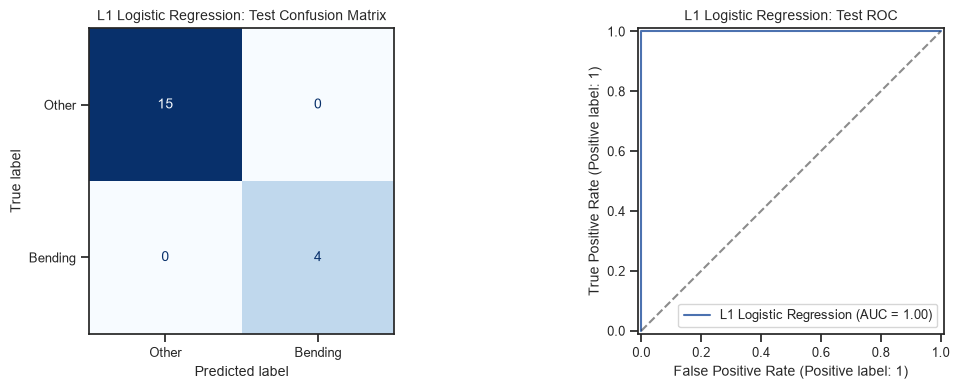

In [21]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
import matplotlib.pyplot as plt

X_test_best_l1 = pd.DataFrame(
    [
        extract_segment_features(df, best_l_l1)
        for df in test_instances
    ],
    index=test_ids,
)

X_test_best_l1 = X_test_best_l1.loc[:, X_train_best_l1.columns]

train_pred_l1 = best_l1_model.predict(X_train_best_l1)
test_pred_l1 = best_l1_model.predict(X_test_best_l1)
test_scores_l1 = best_l1_model.decision_function(X_test_best_l1)

train_accuracy_l1 = accuracy_score(y_train_binary, train_pred_l1)
test_accuracy_l1 = accuracy_score(y_test_binary, test_pred_l1)
test_auc_l1 = roc_auc_score(y_test_binary, test_scores_l1)
test_recall_l1 = recall_score(y_test_binary, test_pred_l1)
test_cm_l1 = confusion_matrix(
    y_test_binary, test_pred_l1, labels=[0, 1]
)

print("Test feature shape:", X_test_best_l1.shape)
print(f"Training accuracy: {train_accuracy_l1:.4f}")
print(f"Test accuracy: {test_accuracy_l1:.4f}")
print(f"Test error: {1 - test_accuracy_l1:.4f}")
print(f"Test AUC: {test_auc_l1:.4f}")
print(f"Test bending recall: {test_recall_l1:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm_l1,
    display_labels=["Other", "Bending"],
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("L1 Logistic Regression: Test Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test_binary,
    test_scores_l1,
    name="L1 Logistic Regression",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("L1 Logistic Regression: Test ROC")

plt.tight_layout()
plt.show()

In [22]:
comparison_binary = pd.DataFrame([
    {
        "model": "Logistic Regression with RFE",
        "segments": best_l_rfe,
        "selected_features": len(selected_features_rfe),
        "CV_accuracy": best_cv_accuracy_rfe,
        "training_accuracy": train_accuracy_rfe,
        "test_accuracy": test_accuracy_rfe,
        "test_AUC": test_auc_rfe,
        "test_bending_recall": recall_score(
            y_test_binary, test_pred_rfe
        ),
    },
    {
        "model": "L1 Logistic Regression",
        "segments": best_l_l1,
        "selected_features": len(selected_features_l1),
        "CV_accuracy": best_cv_accuracy_l1,
        "training_accuracy": train_accuracy_l1,
        "test_accuracy": test_accuracy_l1,
        "test_AUC": test_auc_l1,
        "test_bending_recall": test_recall_l1,
    },
]).set_index("model")

display(comparison_binary.round(4))

,segments,selected_features,CV_accuracy,training_accuracy,test_accuracy,test_AUC,test_bending_recall
model,,,,,,,
Logistic Regression with RFE,19,7,0.9857,1.0,0.9474,0.9,0.75
L1 Logistic Regression,1,8,0.9714,1.0,1.0000,1.0,1.00


L1 logistic regression correctly classified all 19 test instances.
Its test accuracy and AUC were both 1.00.
RFE correctly classified 18 of 19 test instances.
Its test accuracy was 94.74%, and its AUC was 0.90.

RFE had a higher cross-validation accuracy: 98.57%, compared with
97.14% for L1. However, L1 performed better on this test set.
The test set is small, so these results may change with new data.

L1 used 8 features without splitting the time series.
RFE used 7 features after splitting each time series into 19 parts.

L1 was easier to use in this experiment because it selected features
during model fitting. RFE needed a separate feature removal process.
Also, complete separation made the usual p-values unreliable for
the earlier unpenalized model.

### (c) Multiclass Classification

#### (i) L1-Penalized Multinomial Logistic Regression

The goal is to classify all seven activities.
I keep the same training and test sets.

I use 4-fold stratified cross-validation because bending2 has only
4 training instances. This allows every validation fold to include
all seven activities.

I will choose the segment count and C using cross-validation.
Feature scaling will be fitted only on the training part of each fold.

In [23]:
from sklearn.model_selection import StratifiedKFold

y_train_multi = metadata.loc[train_ids, "activity"].to_numpy()
y_test_multi = metadata.loc[test_ids, "activity"].to_numpy()

class_names = np.sort(np.unique(y_train_multi))

class_counts_multi = pd.DataFrame({
    "train": pd.Series(y_train_multi).value_counts(),
    "test": pd.Series(y_test_multi).value_counts(),
}).reindex(class_names).fillna(0).astype(int)

class_counts_multi.index.name = "activity"
display(class_counts_multi)

cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42,
)

cv_splits_multi = list(
    cv_multi.split(
        np.zeros((len(y_train_multi), 1)),
        y_train_multi,
    )
)

fold_counts_multi = pd.DataFrame({
    f"fold_{fold}": pd.Series(
        y_train_multi[validation_positions]
    ).value_counts()
    for fold, (_, validation_positions)
    in enumerate(cv_splits_multi, start=1)
}).reindex(class_names).fillna(0).astype(int)

fold_counts_multi.index.name = "activity"

print("Training instances:", len(y_train_multi))
print("Test instances:", len(y_test_multi))
print("Number of classes:", len(class_names))
print("\nValidation class counts:")
display(fold_counts_multi)

assert (fold_counts_multi > 0).all().all()

,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


Training instances: 69
Test instances: 19
Number of classes: 7

Validation class counts:


,fold_1,fold_2,fold_3,fold_4
activity,,,,
bending1,2,1,1,1
bending2,1,1,1,1
cycling,3,3,3,3
lying,3,3,3,3
sitting,3,3,3,3
standing,3,3,3,3
walking,3,3,3,3


I test segment counts from 1 to 20 and 13 values of C.
I use StandardScaler inside the pipeline to avoid data leakage.

I choose the model with the highest mean cross-validation accuracy.
If models have the same score, I choose fewer segments, then a smaller C.

I use the saga solver because it supports L1-penalized multinomial
logistic regression. The test set is not used to choose the model.

In [24]:
import time
from joblib import parallel_config
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

C_values_multi = np.logspace(-3, 3, 13)

multi_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(
        l1_ratio=1,
        solver="saga",
        max_iter=20000,
        tol=1e-4,
        random_state=42,
    )),
])

multi_models_by_l = {}
multi_cv_results_by_l = {}
multi_records = []

start_time = time.perf_counter()

with parallel_config(
    backend="loky",
    inner_max_num_threads=1,
):
    for l in range(1, 21):
        X = train_features_by_l[l]

        search = GridSearchCV(
            estimator=multi_pipeline,
            param_grid={"logistic__C": C_values_multi},
            scoring="accuracy",
            cv=cv_splits_multi,
            refit=True,
            n_jobs=4,
            error_score="raise",
        )

        search.fit(X, y_train_multi)

        fitted_model = search.best_estimator_
        coefficients = fitted_model.named_steps["logistic"].coef_

        used_features = np.any(coefficients != 0, axis=0)

        multi_models_by_l[l] = fitted_model

        multi_cv_results_by_l[l] = pd.DataFrame({
            "C": [
                params["logistic__C"]
                for params in search.cv_results_["params"]
            ],
            "cv_accuracy": search.cv_results_["mean_test_score"],
            "cv_std": search.cv_results_["std_test_score"],
        })

        best_index = search.best_index_

        multi_records.append({
            "l": l,
            "best_C": search.best_params_["logistic__C"],
            "cv_accuracy": search.best_score_,
            "cv_std": search.cv_results_[
                "std_test_score"
            ][best_index],
            "used_features": int(used_features.sum()),
            "total_features": X.shape[1],
        })

        print(
            f"l={l:2d} | "
            f"C={search.best_params_['logistic__C']:.4g} | "
            f"CV accuracy={search.best_score_:.4f} | "
            f"Used features={used_features.sum()}",
            flush=True,
        )

multi_summary = (
    pd.DataFrame(multi_records)
    .sort_values(
        ["cv_accuracy", "l", "best_C"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

elapsed = time.perf_counter() - start_time
print(f"\nTotal time: {elapsed / 60:.2f} minutes")

display(multi_summary.round(4))

l= 1 | C=10 | CV accuracy=0.9134 | Used features=31
l= 2 | C=3.162 | CV accuracy=0.9003 | Used features=37
l= 3 | C=100 | CV accuracy=0.8415 | Used features=124
l= 4 | C=1000 | CV accuracy=0.8693 | Used features=168
l= 5 | C=316.2 | CV accuracy=0.8832 | Used features=210
l= 6 | C=100 | CV accuracy=0.8979 | Used features=252
l= 7 | C=10 | CV accuracy=0.8538 | Used features=168
l= 8 | C=1000 | CV accuracy=0.8685 | Used features=336
l= 9 | C=31.62 | CV accuracy=0.8546 | Used features=311
l=10 | C=100 | CV accuracy=0.8391 | Used features=419
l=11 | C=0.3162 | CV accuracy=0.7672 | Used features=44
l=12 | C=100 | CV accuracy=0.8554 | Used features=504
l=13 | C=316.2 | CV accuracy=0.8407 | Used features=546
l=14 | C=10 | CV accuracy=0.7966 | Used features=337
l=15 | C=316.2 | CV accuracy=0.8685 | Used features=630
l=16 | C=100 | CV accuracy=0.8113 | Used features=672
l=17 | C=316.2 | CV accuracy=0.8113 | Used features=714
l=18 | C=100 | CV accuracy=0.8832 | Used features=752
l=19 | C=100 | CV

,l,best_C,cv_accuracy,cv_std,used_features,total_features
0,1,10.0000,0.9134,0.0279,31,42
1,2,3.1623,0.9003,0.0821,37,84
2,6,100.0000,0.8979,0.0495,252,252
3,5,316.2278,0.8832,0.0428,210,210
4,18,100.0000,0.8832,0.0428,752,756
5,4,1000.0000,0.8693,0.0645,168,168
6,8,1000.0000,0.8685,0.0500,336,336
7,15,316.2278,0.8685,0.0500,630,630
8,12,100.0000,0.8554,0.0272,504,504
9,9,31.6228,0.8546,0.0520,311,378


In [25]:
best_result_multi = multi_summary.iloc[0]

best_l_multi = int(best_result_multi["l"])
best_C_multi = float(best_result_multi["best_C"])
best_cv_accuracy_multi = float(best_result_multi["cv_accuracy"])

best_multi_model = multi_models_by_l[best_l_multi]
X_train_best_multi = train_features_by_l[best_l_multi]

multi_coefficients = best_multi_model.named_steps["logistic"].coef_
multi_feature_mask = np.any(multi_coefficients != 0, axis=0)

selected_features_multi = (
    X_train_best_multi.columns[multi_feature_mask].tolist()
)

print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print(f"Best CV accuracy: {best_cv_accuracy_multi:.4f}")
print("Total input features:", X_train_best_multi.shape[1])
print("Features used by at least one class:", len(selected_features_multi))
print("Coefficient matrix shape:", multi_coefficients.shape)

Best l: 1
Best C: 10.0
Best CV accuracy: 0.9134
Total input features: 42
Features used by at least one class: 31
Coefficient matrix shape: (7, 42)


The best model uses l = 1 and C = 10.
Its mean cross-validation accuracy is 91.34%.
It uses 31 of the 42 features across the seven classes.

In the confusion matrix, rows show the true classes and columns
show the predicted classes. Correct predictions are on the diagonal.

I use one-vs-rest ROC curves. For each curve, one activity is the
positive class, and all other activities are the negative class.
The macro AUC is the average of the seven class AUC values.

References:
- [Confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [Multiclass ROC](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html)

Test feature shape: (19, 42)
Training accuracy: 1.0000
CV accuracy: 0.9134
Test accuracy: 0.9474
Test error: 0.0526
Test macro AUC (OvR): 0.9940
Correct test predictions: 18 out of 19


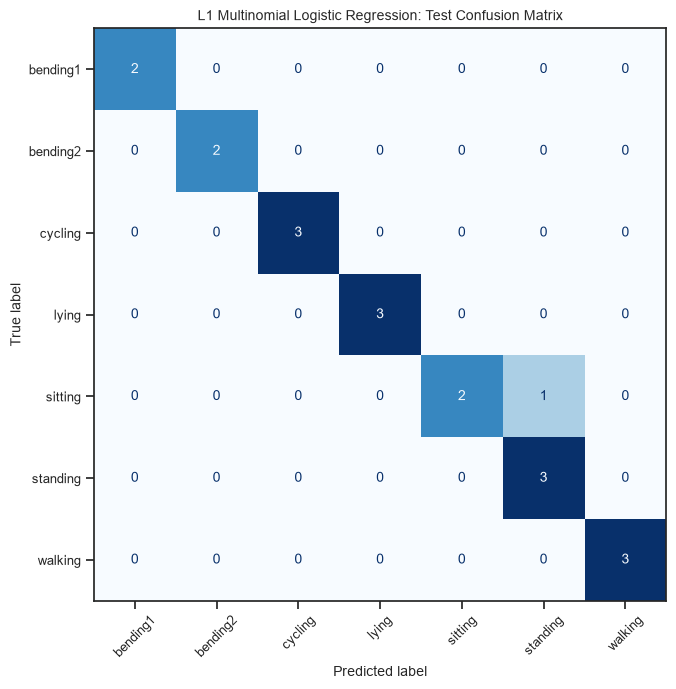

In [26]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

X_test_best_multi = pd.DataFrame(
    [
        extract_segment_features(df, best_l_multi)
        for df in test_instances
    ],
    index=test_ids,
).loc[:, X_train_best_multi.columns]

train_pred_multi = best_multi_model.predict(X_train_best_multi)
test_pred_multi = best_multi_model.predict(X_test_best_multi)
test_prob_multi = best_multi_model.predict_proba(X_test_best_multi)

multi_classes = best_multi_model.classes_

train_accuracy_multi = accuracy_score(
    y_train_multi, train_pred_multi
)
test_accuracy_multi = accuracy_score(
    y_test_multi, test_pred_multi
)
test_error_multi = 1 - test_accuracy_multi

test_auc_multi = roc_auc_score(
    y_test_multi,
    test_prob_multi,
    labels=multi_classes,
    multi_class="ovr",
    average="macro",
)

test_cm_multi = confusion_matrix(
    y_test_multi,
    test_pred_multi,
    labels=multi_classes,
)

print("Test feature shape:", X_test_best_multi.shape)
print(f"Training accuracy: {train_accuracy_multi:.4f}")
print(f"CV accuracy: {best_cv_accuracy_multi:.4f}")
print(f"Test accuracy: {test_accuracy_multi:.4f}")
print(f"Test error: {test_error_multi:.4f}")
print(f"Test macro AUC (OvR): {test_auc_multi:.4f}")
print(
    "Correct test predictions:",
    int(np.sum(test_pred_multi == y_test_multi)),
    "out of",
    len(y_test_multi),
)

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm_multi,
    display_labels=multi_classes,
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    xticks_rotation=45,
    values_format="d",
)

ax.set_title("L1 Multinomial Logistic Regression: Test Confusion Matrix")
plt.tight_layout()
plt.show()

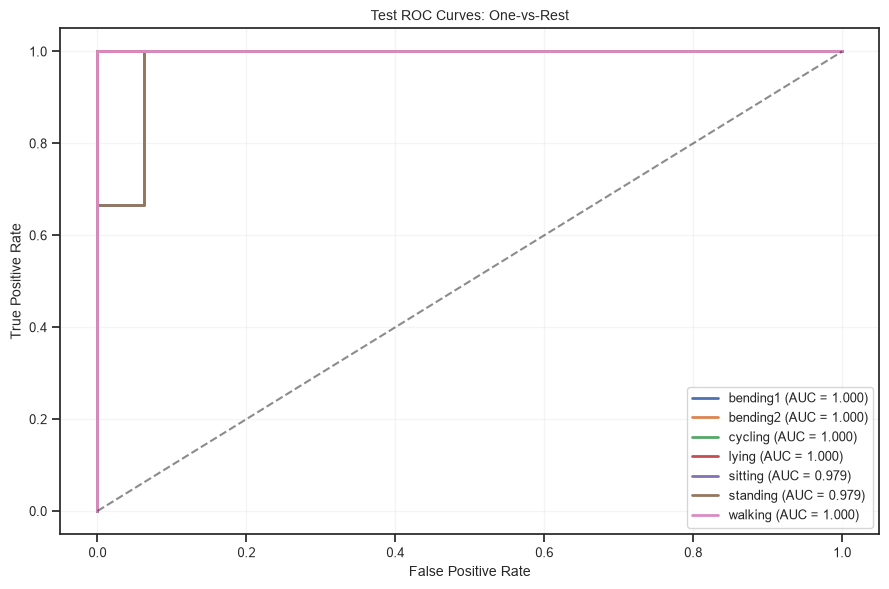

,test_instances,AUC
activity,,
bending1,2,1.0000
bending2,2,1.0000
cycling,3,1.0000
lying,3,1.0000
sitting,3,0.9792
standing,3,0.9792
walking,3,1.0000


In [27]:
y_test_multi_binary = label_binarize(
    y_test_multi,
    classes=multi_classes,
)

auc_records_multi = []

fig, ax = plt.subplots(figsize=(9, 6))

for i, activity in enumerate(multi_classes):
    true_binary = y_test_multi_binary[:, i]
    probabilities = test_prob_multi[:, i]

    fpr, tpr, _ = roc_curve(true_binary, probabilities)
    class_auc = roc_auc_score(true_binary, probabilities)

    auc_records_multi.append({
        "activity": activity,
        "test_instances": int(true_binary.sum()),
        "AUC": class_auc,
    })

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{activity} (AUC = {class_auc:.3f})",
    )

ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Test ROC Curves: One-vs-Rest")
ax.legend(loc="lower right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

auc_table_multi = pd.DataFrame(
    auc_records_multi
).set_index("activity")

display(auc_table_multi.round(4))

In [28]:
test_predictions_multi = metadata.loc[
    test_ids, ["activity", "filename"]
].copy()

test_predictions_multi["predicted_activity"] = test_pred_multi
test_predictions_multi["correct"] = (
    test_predictions_multi["activity"]
    == test_predictions_multi["predicted_activity"]
)

mistakes_multi = test_predictions_multi.loc[
    ~test_predictions_multi["correct"]
]

print("Number of test mistakes:", len(mistakes_multi))
display(mistakes_multi)

Number of test mistakes: 1


,activity,filename,predicted_activity,correct
51,sitting,dataset3.csv,standing,False


The model correctly classified 18 of the 19 test instances.
The test accuracy was 94.74%, and the test error was 5.26%.
The training accuracy was 100%, and the cross-validation accuracy
was 91.34%.

The only mistake was sitting/dataset3.csv, which was predicted
as standing.

The macro one-vs-rest AUC was 0.9940. Sitting and standing each
had an AUC of 0.9792. The other five classes had an AUC of 1.00.

These results show strong performance on this test set.
However, each activity has only two or three test instances,
so the results may change with more data.

#### (ii) Gaussian and Multinomial Naive Bayes

I compare Gaussian Naive Bayes and Multinomial Naive Bayes.
Both models assume that features are independent within each class.

Gaussian Naive Bayes assumes a Gaussian distribution for each
feature within each class.

Multinomial Naive Bayes usually works with count data.
Here, I use the nonnegative time-domain features as weights.
These features are not actual counts, so this is an approximate use
of the model.

I use the original features without scaling for both models.
I test segment counts from 1 to 20 using the same 4-fold splits.
I also choose var_smoothing for Gaussian Naive Bayes and alpha
for Multinomial Naive Bayes through cross-validation.

I choose the highest mean cross-validation accuracy.
For tied scores, I choose fewer segments, then the smaller
smoothing parameter. The test set is not used for model selection.

In [29]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import GridSearchCV
import time

nb_settings = {
    "GaussianNB": {
        "estimator": GaussianNB(),
        "parameter": "var_smoothing",
        "values": np.logspace(-9, -1, 9),
    },
    "MultinomialNB": {
        "estimator": MultinomialNB(),
        "parameter": "alpha",
        "values": np.logspace(-3, 2, 6),
    },
}

nb_models_by_l = {name: {} for name in nb_settings}
nb_cv_results_by_l = {name: {} for name in nb_settings}
nb_records = []

start_time_nb = time.perf_counter()

for name, settings in nb_settings.items():
    parameter = settings["parameter"]

    for l in range(1, 21):
        X = train_features_by_l[l]

        if name == "MultinomialNB":
            assert (X.to_numpy() >= 0).all(), (
                "MultinomialNB input contains negative values."
            )

        search = GridSearchCV(
            estimator=settings["estimator"],
            param_grid={parameter: settings["values"]},
            scoring="accuracy",
            cv=cv_splits_multi,
            refit=True,
            n_jobs=1,
            error_score="raise",
        )

        search.fit(X, y_train_multi)

        nb_models_by_l[name][l] = search.best_estimator_

        nb_cv_results_by_l[name][l] = pd.DataFrame({
            parameter: [
                params[parameter]
                for params in search.cv_results_["params"]
            ],
            "cv_accuracy": search.cv_results_["mean_test_score"],
            "cv_std": search.cv_results_["std_test_score"],
        })

        nb_records.append({
            "model": name,
            "l": l,
            "parameter": parameter,
            "best_parameter": search.best_params_[parameter],
            "cv_accuracy": search.best_score_,
            "cv_std": search.cv_results_[
                "std_test_score"
            ][search.best_index_],
        })

    print(f"{name}: finished all 20 segment counts.", flush=True)

nb_summary = (
    pd.DataFrame(nb_records)
    .sort_values(
        ["model", "cv_accuracy", "l", "best_parameter"],
        ascending=[True, False, True, True],
    )
    .reset_index(drop=True)
)

elapsed_nb = time.perf_counter() - start_time_nb
print(f"\nTotal time: {elapsed_nb:.2f} seconds")

for name in nb_settings:
    print(f"\n{name}:")
    display(
        nb_summary.loc[nb_summary["model"] == name]
        .reset_index(drop=True)
    )

GaussianNB: finished all 20 segment counts.
MultinomialNB: finished all 20 segment counts.

Total time: 4.20 seconds

GaussianNB:


,model,l,parameter,best_parameter,cv_accuracy,cv_std
0,GaussianNB,1,var_smoothing,0.0100,0.927288,0.049040
1,GaussianNB,5,var_smoothing,0.0010,0.898693,0.063788
2,GaussianNB,2,var_smoothing,0.0100,0.897876,0.026886
3,GaussianNB,3,var_smoothing,0.0100,0.883170,0.042758
4,GaussianNB,4,var_smoothing,0.0100,0.883170,0.042758
5,GaussianNB,8,var_smoothing,0.0100,0.883170,0.059652
6,GaussianNB,6,var_smoothing,0.0100,0.868464,0.077209
7,GaussianNB,7,var_smoothing,0.0100,0.868464,0.077209
8,GaussianNB,9,var_smoothing,0.0100,0.868464,0.077209
9,GaussianNB,11,var_smoothing,0.0001,0.855392,0.064801



MultinomialNB:


,model,l,parameter,best_parameter,cv_accuracy,cv_std
0,MultinomialNB,1,alpha,1.000,0.839869,0.077403
1,MultinomialNB,14,alpha,0.001,0.825163,0.073420
2,MultinomialNB,17,alpha,0.001,0.825163,0.073420
3,MultinomialNB,16,alpha,1.000,0.811275,0.064801
4,MultinomialNB,5,alpha,0.100,0.810458,0.078022
5,MultinomialNB,7,alpha,1.000,0.810458,0.066010
6,MultinomialNB,13,alpha,0.001,0.810458,0.078022
7,MultinomialNB,2,alpha,0.010,0.810458,0.097712
8,MultinomialNB,11,alpha,0.001,0.810458,0.097712
9,MultinomialNB,19,alpha,0.001,0.810458,0.097712


In [30]:
best_nb_results = (
    nb_summary.groupby("model", sort=False)
    .head(1)
    .set_index("model")
)

best_nb_models = {}
best_nb_l = {}

for name in nb_settings:
    chosen_l = int(best_nb_results.loc[name, "l"])

    best_nb_l[name] = chosen_l
    best_nb_models[name] = nb_models_by_l[name][chosen_l]

display(best_nb_results)

,l,parameter,best_parameter,cv_accuracy,cv_std
model,,,,,
GaussianNB,1,var_smoothing,0.01,0.927288,0.049040
MultinomialNB,1,alpha,1.00,0.839869,0.077403


Gaussian Naive Bayes selected l = 1 and var_smoothing = 0.01.
Its mean cross-validation accuracy was 92.73%.

Multinomial Naive Bayes selected l = 1 and alpha = 1.
Its mean cross-validation accuracy was 83.99%.

I now evaluate both fitted models on the test set.
I report test error, confusion matrices, and one-vs-rest ROC curves.

For Naive Bayes ROC curves, I use log probabilities to reduce
numerical problems with very small probabilities. Taking the log
preserves the order of positive probability values.

In [31]:
nb_test_results = {}
nb_evaluation_records = []
nb_auc_records = []

for name, model in best_nb_models.items():
    l = best_nb_l[name]
    X_train_nb = train_features_by_l[l]

    X_test_nb = pd.DataFrame(
        [
            extract_segment_features(df, l)
            for df in test_instances
        ],
        index=test_ids,
    ).loc[:, X_train_nb.columns]

    if name == "MultinomialNB":
        assert (X_test_nb.to_numpy() >= 0).all()

    train_pred_nb = model.predict(X_train_nb)
    test_pred_nb = model.predict(X_test_nb)

    test_log_prob_nb = model.predict_log_proba(X_test_nb)
    assert np.isfinite(test_log_prob_nb).all()

    classes_nb = model.classes_
    y_binary_nb = label_binarize(
        y_test_multi,
        classes=classes_nb,
    )

    class_auc_values = []

    for i, activity in enumerate(classes_nb):
        class_auc = roc_auc_score(
            y_binary_nb[:, i],
            test_log_prob_nb[:, i],
        )

        class_auc_values.append(class_auc)
        nb_auc_records.append({
            "model": name,
            "activity": activity,
            "AUC": class_auc,
        })

    test_accuracy_nb = accuracy_score(
        y_test_multi, test_pred_nb
    )

    nb_evaluation_records.append({
        "model": name,
        "l": l,
        "CV_accuracy": best_nb_results.loc[name, "cv_accuracy"],
        "training_accuracy": accuracy_score(
            y_train_multi, train_pred_nb
        ),
        "test_accuracy": test_accuracy_nb,
        "test_error": 1 - test_accuracy_nb,
        "test_macro_AUC": np.mean(class_auc_values),
        "test_mistakes": int(
            np.sum(test_pred_nb != y_test_multi)
        ),
    })

    nb_test_results[name] = {
        "classes": classes_nb,
        "predictions": test_pred_nb,
        "log_probabilities": test_log_prob_nb,
        "binary_labels": y_binary_nb,
        "confusion_matrix": confusion_matrix(
            y_test_multi,
            test_pred_nb,
            labels=classes_nb,
        ),
    }

nb_evaluation = pd.DataFrame(
    nb_evaluation_records
).set_index("model")

display(nb_evaluation.round(4))

,l,CV_accuracy,training_accuracy,test_accuracy,test_error,test_macro_AUC,test_mistakes
model,,,,,,,
GaussianNB,1,0.9273,0.9710,1.0000,0.0000,1.0000,0
MultinomialNB,1,0.8399,0.9275,0.8947,0.1053,0.9851,2


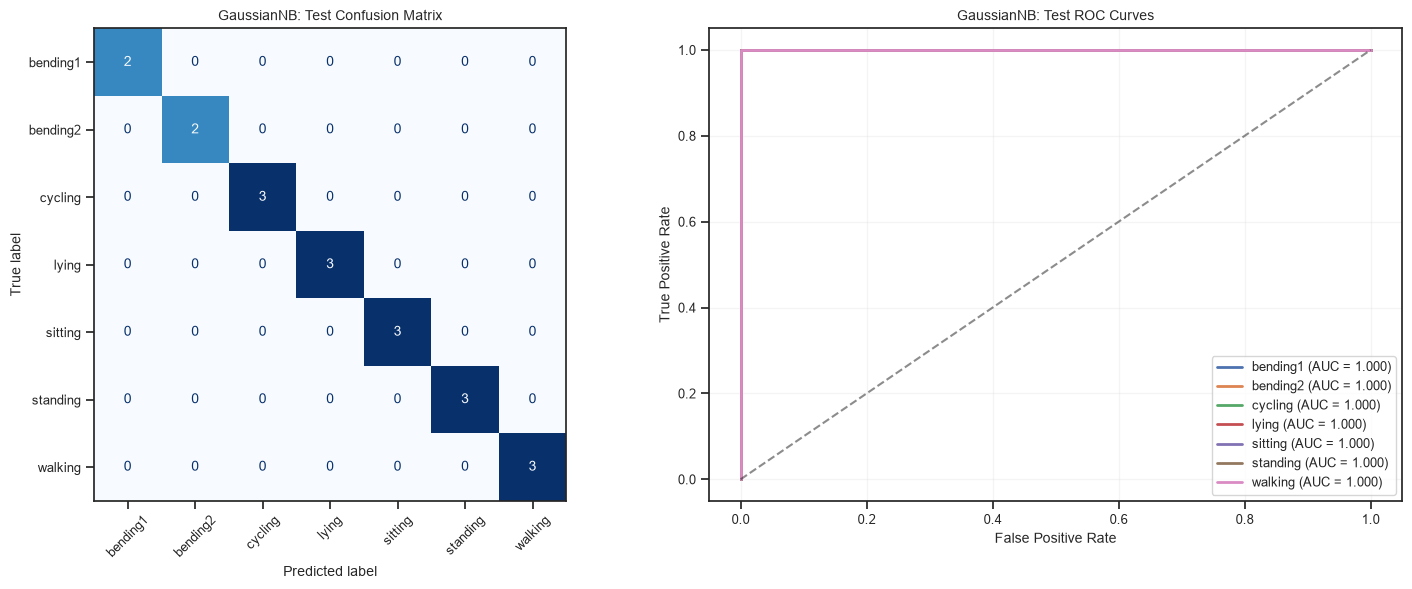

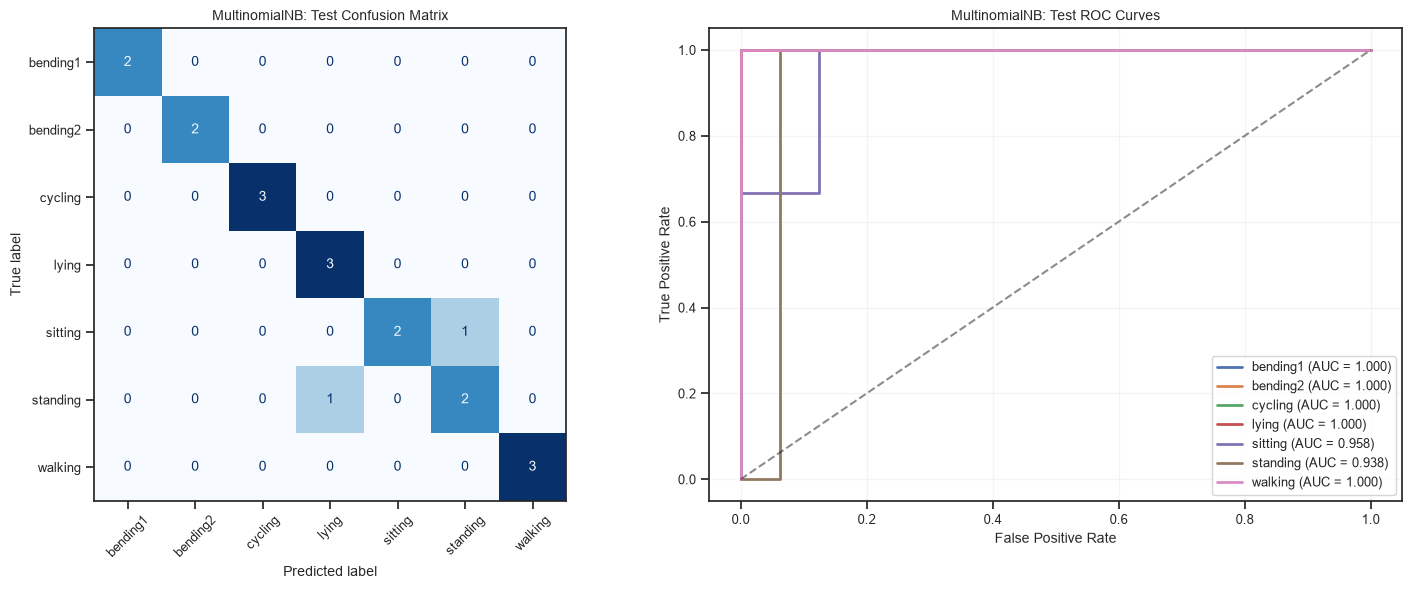

model,GaussianNB,MultinomialNB
activity,,
bending1,1.0,1.0000
bending2,1.0,1.0000
cycling,1.0,1.0000
lying,1.0,1.0000
sitting,1.0,0.9583
standing,1.0,0.9375
walking,1.0,1.0000


In [32]:
for name, result in nb_test_results.items():
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=result["classes"],
    ).plot(
        ax=axes[0],
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        values_format="d",
    )

    axes[0].set_title(f"{name}: Test Confusion Matrix")

    for i, activity in enumerate(result["classes"]):
        true_binary = result["binary_labels"][:, i]
        scores = result["log_probabilities"][:, i]

        fpr, tpr, _ = roc_curve(true_binary, scores)
        class_auc = roc_auc_score(true_binary, scores)

        axes[1].plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{activity} (AUC = {class_auc:.3f})",
        )

    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"{name}: Test ROC Curves")
    axes[1].legend(loc="lower right", fontsize=9)
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

nb_auc_table = pd.DataFrame(nb_auc_records).pivot(
    index="activity",
    columns="model",
    values="AUC",
)

display(nb_auc_table.round(4))

In [33]:
logistic_comparison_row = pd.DataFrame([{
    "model": "L1 Multinomial Logistic Regression",
    "l": best_l_multi,
    "CV_accuracy": best_cv_accuracy_multi,
    "training_accuracy": train_accuracy_multi,
    "test_accuracy": test_accuracy_multi,
    "test_error": test_error_multi,
    "test_macro_AUC": test_auc_multi,
    "test_mistakes": int(
        np.sum(test_pred_multi != y_test_multi)
    ),
}]).set_index("model")

comparison_multiclass = pd.concat([
    logistic_comparison_row,
    nb_evaluation,
])

display(comparison_multiclass.round(4))

for name, result in nb_test_results.items():
    predictions = metadata.loc[
        test_ids, ["activity", "filename"]
    ].copy()

    predictions["predicted_activity"] = result["predictions"]

    mistakes = predictions.loc[
        predictions["activity"]
        != predictions["predicted_activity"]
    ]

    print(f"\n{name}: {len(mistakes)} test mistakes")
    display(mistakes)

,l,CV_accuracy,training_accuracy,test_accuracy,test_error,test_macro_AUC,test_mistakes
model,,,,,,,
L1 Multinomial Logistic Regression,1,0.9134,1.0000,0.9474,0.0526,0.9940,1
GaussianNB,1,0.9273,0.9710,1.0000,0.0000,1.0000,0
MultinomialNB,1,0.8399,0.9275,0.8947,0.1053,0.9851,2



GaussianNB: 0 test mistakes


,activity,filename,predicted_activity



MultinomialNB: 2 test mistakes


,activity,filename,predicted_activity
43,sitting,dataset1.csv,standing
58,standing,dataset1.csv,lying


Gaussian Naive Bayes performed better than Multinomial Naive Bayes
in this experiment.

Gaussian Naive Bayes correctly classified all 19 test instances.
Its test error was 0%, and its macro AUC was 1.00.
Its cross-validation accuracy was 92.73%.

Multinomial Naive Bayes correctly classified 17 of 19 test instances.
Its test error was 10.53%, and its macro AUC was 0.9851.
Its cross-validation accuracy was 83.99%.

Multinomial Naive Bayes made two mistakes:
- sitting/dataset1.csv was predicted as standing.
- standing/dataset1.csv was predicted as lying.

Our features are continuous measurements rather than counts.
This may help explain why Gaussian Naive Bayes performed better.
However, these results do not prove that the features follow
Gaussian distributions or are independent within each class.

#### (iii) Which Method Is Better?

Gaussian Naive Bayes was the best of the three methods in this
experiment. It had the highest cross-validation accuracy at 92.73%.
It also had the lowest test error at 0% and the highest macro AUC
at 1.00.

L1 multinomial logistic regression was second in test accuracy.
It made one test mistake. Multinomial Naive Bayes made two.

All three methods selected l = 1, so splitting the time series
did not improve their best cross-validation results in this search.

Based on these results, I would choose Gaussian Naive Bayes
for this task. However, the test set has only 19 instances.
More data would be needed to check whether this advantage holds.

## 3. ISLR 4.8.3

Let $\pi_k = P(Y=k)$ be the prior probability of class $k$.
For each class, assume

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
$$

The classes may have different variances.

### Step 1: Apply Bayes' theorem

The probability of class $k$ given $X=x$ is

$$
P(Y=k \mid X=x)
=
\frac{\pi_k f_k(x)}
{\sum_{j=1}^{K}\pi_j f_j(x)}.
$$

The denominator is the same for every class.
Therefore, the Bayes classifier chooses the class with the largest
$\pi_k f_k(x)$.

### Step 2: Use the Gaussian density

For class $k$, the density is

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking the log keeps the same order of values:

$$
\log[\pi_k f_k(x)]
=
\log\pi_k
-\frac{1}{2}\log(2\pi)
-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

The term $-\frac{1}{2}\log(2\pi)$ is the same for every class.
We can remove it when comparing classes.

The discriminant function is therefore

$$
\delta_k(x)
=
\log\pi_k-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

### Step 3: Expand the square

Expanding $(x-\mu_k)^2$ gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
+\log\pi_k-\log\sigma_k.
$$

This function contains an $x^2$ term.
Its coefficient depends on the class variance.

To compare classes $k$ and $j$, we examine
$\delta_k(x)-\delta_j(x)$.
The coefficient of $x^2$ in this difference is

$$
\frac{1}{2\sigma_j^2}
-
\frac{1}{2\sigma_k^2}.
$$

When $\sigma_k^2 \ne \sigma_j^2$, this coefficient is not zero.
The equation $\delta_k(x)=\delta_j(x)$ is therefore quadratic in $x$.

Thus, with different class variances, the Bayes classifier is
generally quadratic. This gives Quadratic Discriminant Analysis (QDA).

If all classes have the same variance, the $x^2$ terms cancel
when comparing classes. The discriminant functions can then
be written as linear functions, as in Linear Discriminant Analysis (LDA).

## 4. ISLR 4.8.7

Let $Y=\text{Yes}$ mean that a company issues a dividend.
The given prior probabilities are

$$
P(Y=\text{Yes})=0.8,
\qquad
P(Y=\text{No})=0.2.
$$

The profit distributions are

$$
X \mid Y=\text{Yes} \sim N(10,36),
$$

$$
X \mid Y=\text{No} \sim N(0,36).
$$

We want to find $P(Y=\text{Yes}\mid X=4)$.

### Step 1: Find the Gaussian densities

For companies that issue dividends,

$$
f_{\text{Yes}}(4)
=
\frac{1}{\sqrt{2\pi\cdot36}}
\exp\left(-\frac{(4-10)^2}{2\cdot36}\right)
\approx 0.040328.
$$

For companies that do not issue dividends,

$$
f_{\text{No}}(4)
=
\frac{1}{\sqrt{2\pi\cdot36}}
\exp\left(-\frac{(4-0)^2}{2\cdot36}\right)
\approx 0.053241.
$$

These values are probability densities, not probabilities.

### Step 2: Apply Bayes' theorem

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

Both densities have the same constant factor, so it cancels:

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8e^{-36/72}}
{0.8e^{-36/72}+0.2e^{-16/72}}
\approx 0.751852.
$$

The predicted probability that the company will issue a dividend
is about **75.19%**.

This is below the prior probability of 80%.
A profit value of 4 has a higher density in the No group,
so this information lowers the probability of Yes.
However, Yes is still more likely because its prior probability
is much higher.

In [35]:
import math

x = 4
variance = 36

prior_yes = 0.8
prior_no = 0.2

mean_yes = 10
mean_no = 0

def gaussian_density(x, mean, variance):
    return (
        math.exp(-((x - mean) ** 2) / (2 * variance))
        / math.sqrt(2 * math.pi * variance)
    )

density_yes = gaussian_density(x, mean_yes, variance)
density_no = gaussian_density(x, mean_no, variance)

probability_yes = (
    prior_yes * density_yes
    / (
        prior_yes * density_yes
        + prior_no * density_no
    )
)

print(f"Density for Yes: {density_yes:.6f}")
print(f"Density for No: {density_no:.6f}")
print(f"Probability of a dividend: {probability_yes:.6f}")
print(f"Percentage: {probability_yes:.2%}")

Density for Yes: 0.040328
Density for No: 0.053241
Probability of a dividend: 0.751852
Percentage: 75.19%
